In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams.update({
    "font.size": 14,          # Общий размер шрифта
    "axes.titlesize": 16,     # Заголовки графиков
    "axes.labelsize": 14,     # Подписи осей
    "xtick.labelsize": 12,    # Подписи делений X
    "ytick.labelsize": 12,    # Подписи делений Y
    "legend.fontsize": 12,    # Легенда
    "figure.titlesize": 18    # Общий заголовок рисунка
})


SEED = 42
N_TRAIN = 10
NOISE_FRACTION = 0.1
M_VALUES = range(16)
NOISE_KINDS = ("uniform", "normal")
X_MIN = 0.0
X_MAX = 2 * np.pi

functions = {
    "cos(x)": np.cos,
    "5x^3 + x^2 + 5": lambda x: 5 * x**3 + x**2 + 5,
    "x sin(x)": lambda x: x * np.sin(x),
}

x_grid = np.linspace(X_MIN, X_MAX, 1000)


def to_z(x):
    """Преобразование x из [0, 2π] в z из [-1, 1]"""
    x = np.asarray(x, dtype=float)
    return (x - np.pi) / np.pi


def noise_sigma(func):
    """Стандартное отклонение шума: 10% от размаха функции на [0, 2π]"""
    y_ref = func(np.linspace(X_MIN, X_MAX, 20_001))
    return NOISE_FRACTION * np.ptp(y_ref)


def make_sample(func, n, noise_kind, rng):
    """Случайная выборка с x ~ Uniform[0, 2π] и одним из двух шумов"""
    x = rng.uniform(X_MIN, X_MAX, size=n)
    sigma = noise_sigma(func)
    if noise_kind == "uniform":
        # D(uniform) = (b-a)^2/12
        # при U(-sqrt(3) * sigma; sqrt(3) * sigma) отклонение шума будет равна sigma
        eps = rng.uniform(-np.sqrt(3) * sigma, np.sqrt(3) * sigma, size=n)
    elif noise_kind == "normal":
        # Дисперсия шума равна sigma
        eps = rng.normal(loc=0.0, scale=sigma, size=n)
    else:
        raise ValueError("noise_kind должен быть 'uniform' или 'normal'")
    y = func(x) + eps
    order = np.argsort(x)
    return {"x": x[order], "y": y[order], "sigma": sigma, "noise_kind": noise_kind}


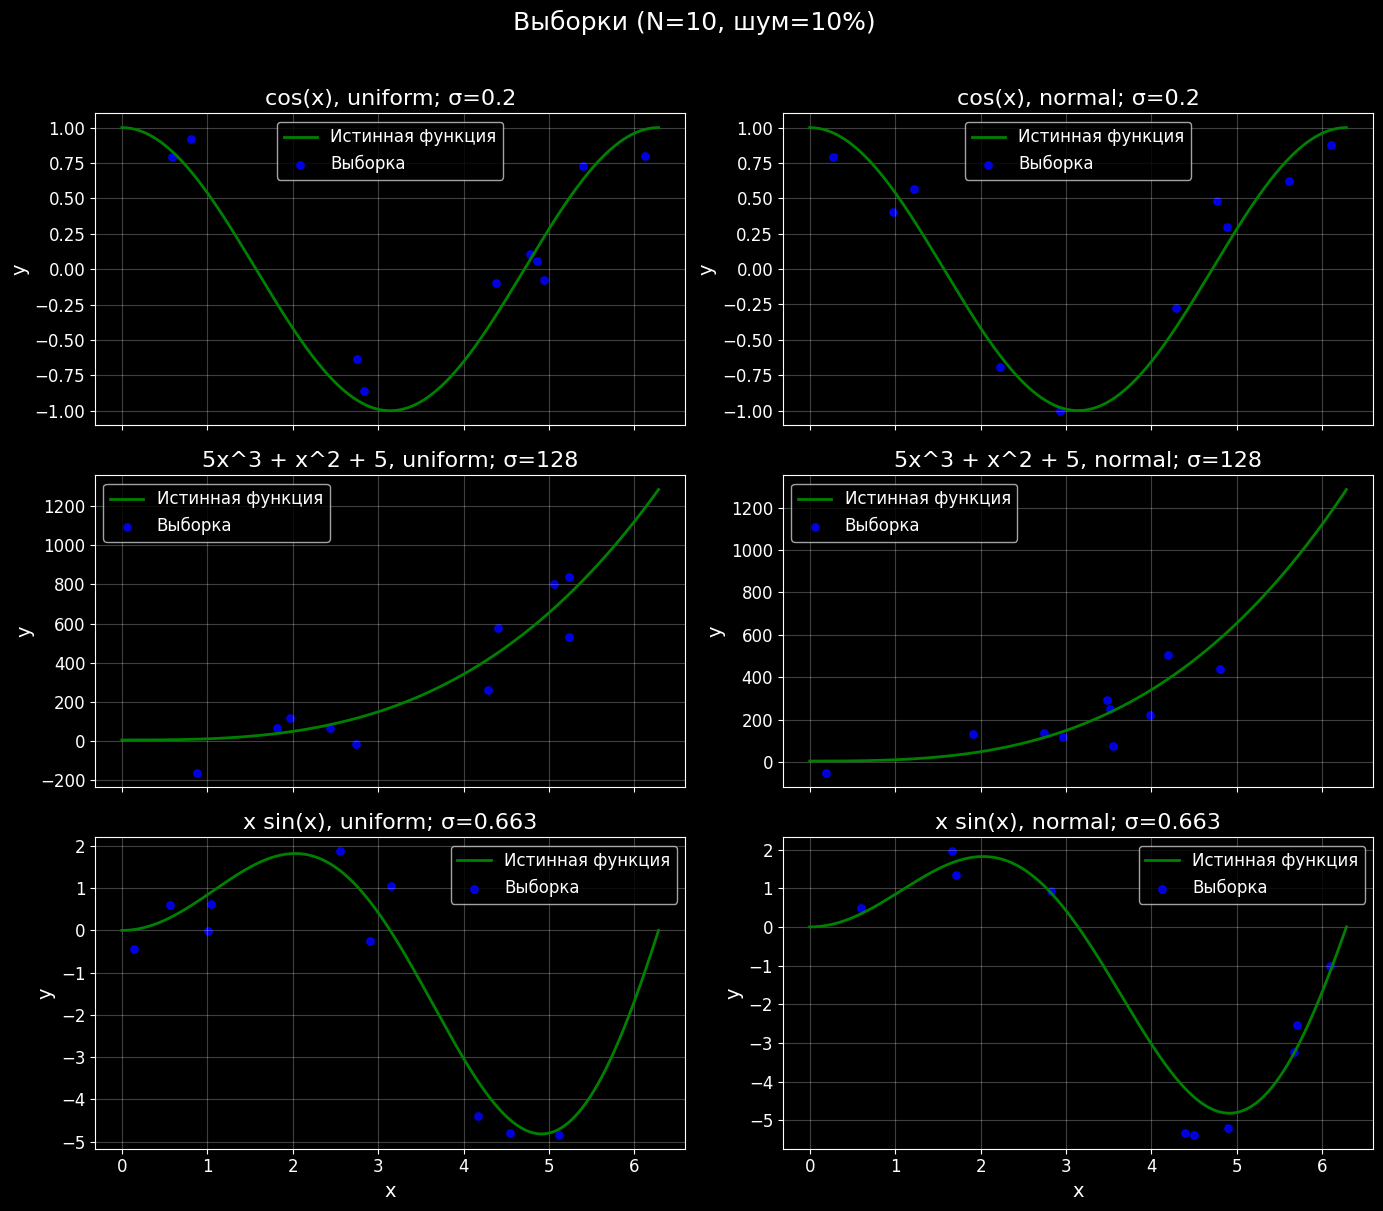

In [2]:
rng = np.random.default_rng(SEED)
samples = {}
for func_name, func in functions.items():
    for kind in NOISE_KINDS:
        samples[(func_name, kind)] = make_sample(func, N_TRAIN, kind, rng)

fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True)
for i, (func_name, func) in enumerate(functions.items()):
    for j, kind in enumerate(NOISE_KINDS):
        ax = axes[i, j]
        sample = samples[(func_name, kind)]
        ax.plot(x_grid, func(x_grid), linewidth=2, label="Истинная функция", color="green")
        ax.scatter(sample["x"], sample["y"], s=28, alpha=0.85, label="Выборка", color="blue")
        ax.set_title(f"{func_name}, {kind}; σ={sample['sigma']:.3g}")
        ax.set_ylabel("y")
        ax.legend()
axes[-1, 0].set_xlabel("x")
axes[-1, 1].set_xlabel("x")
fig.suptitle(f"Выборки (N={N_TRAIN}, шум={int(NOISE_FRACTION * 100)}%)", y=1.01)
plt.tight_layout()
plt.show()

In [3]:
def design_matrix(x, degree):
    """Матрица Вандермонда для степеней z^0, ..., z^M."""
    z = to_z(x)
    return np.polynomial.polynomial.polyvander(z, degree)


def fit_ols(x, y, degree):
    # OLS = Ordinary Least Squares (метод наименьших квадратов)
    """МНК для полинома степени degree; коэффициенты заданы в степенях z."""
    X = design_matrix(x, degree)
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    return coef


def predict_ols(x, coef):
    return design_matrix(x, len(coef) - 1) @ coef


def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


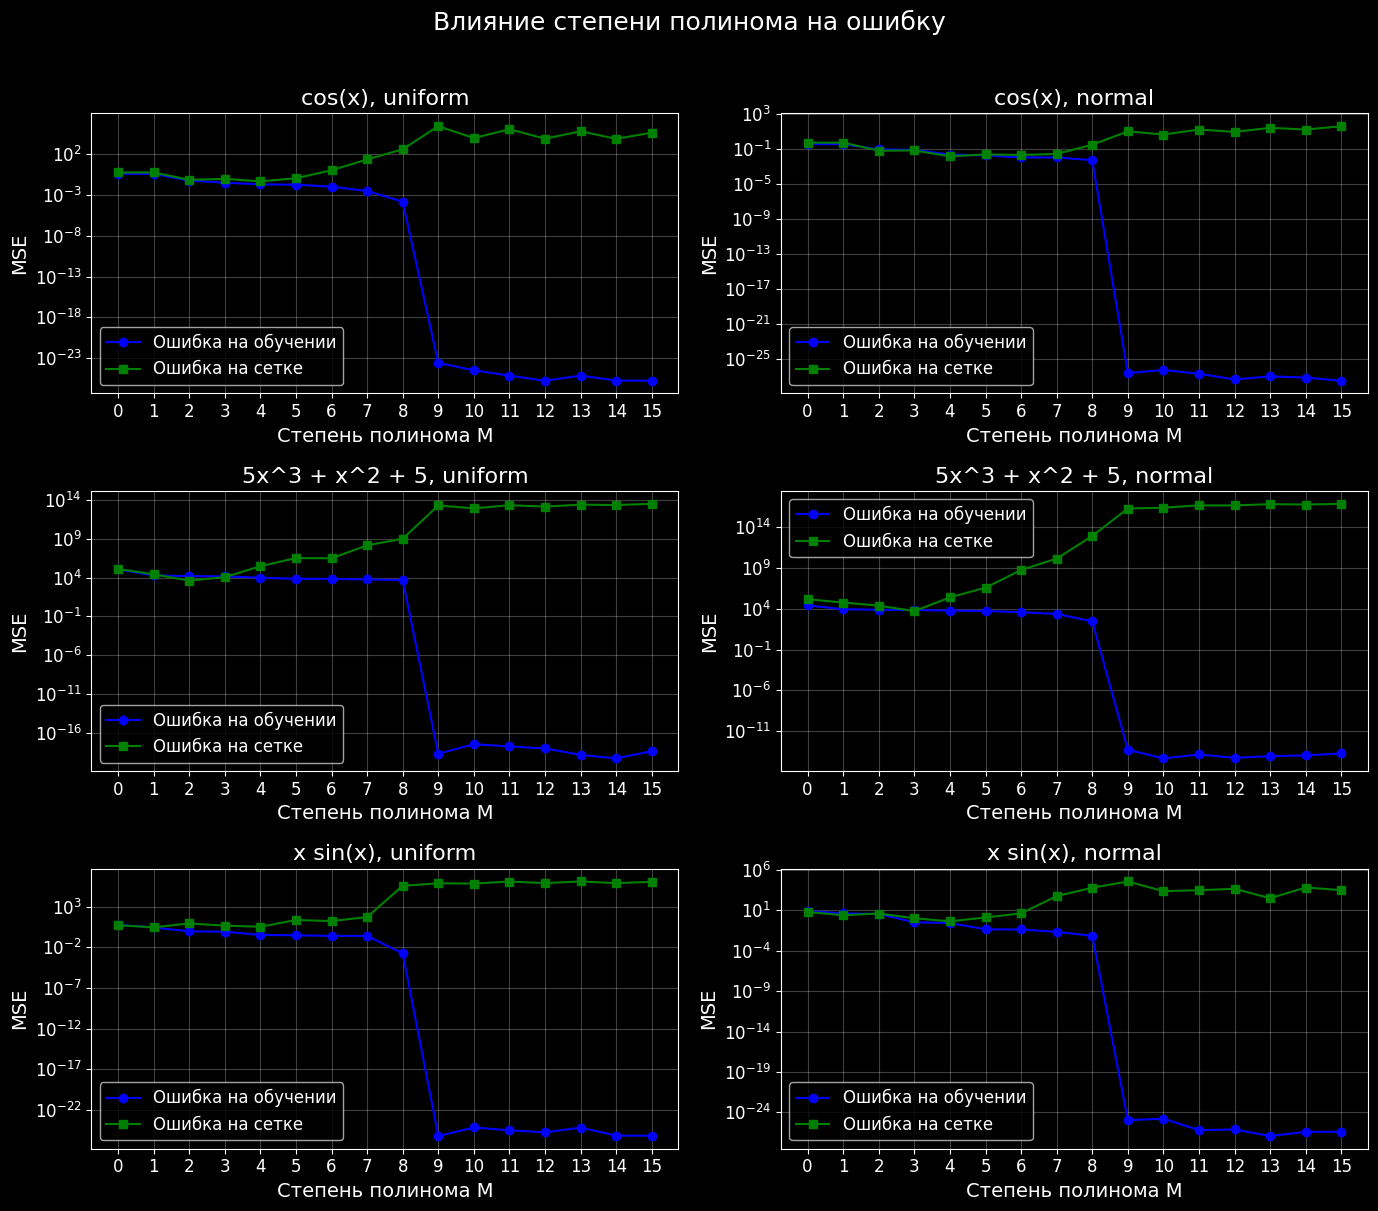

In [4]:
results = {}
for func_name, func in functions.items():
    for kind in NOISE_KINDS:
        sample = samples[(func_name, kind)]
        rows = []
        for degree in M_VALUES:
            coef = fit_ols(sample["x"], sample["y"], degree)
            train_pred = predict_ols(sample["x"], coef)
            grid_pred = predict_ols(x_grid, coef)
            rows.append({
                "M": degree,
                "train_mse": mse(sample["y"], train_pred),
                "true_function_mse": mse(func(x_grid), grid_pred),
                "coef": coef,
            })
        results[(func_name, kind)] = pd.DataFrame(rows)

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for i, (func_name, func) in enumerate(functions.items()):
    for j, kind in enumerate(NOISE_KINDS):
        ax = axes[i, j]
        result = results[(func_name, kind)]
        ax.semilogy(result["M"], result["train_mse"], marker="o", label="Ошибка на обучении", color="blue")
        ax.semilogy(result["M"], result["true_function_mse"], marker="s", label="Ошибка на сетке", color="green")
        ax.set_title(f"{func_name}, {kind}")
        ax.set_xlabel("Степень полинома M")
        ax.set_ylabel("MSE")
        ax.set_xticks(list(M_VALUES))
        ax.legend()
fig.suptitle("Влияние степени полинома на ошибку", y=1.01)
plt.tight_layout()
plt.show()

In [5]:
rows = []

for func_name, func in functions.items():
    for kind in NOISE_KINDS:
        train = samples[(func_name, kind)]
        for degree in M_VALUES:
            coef = fit_ols(train["x"], train["y"], degree)
            train_pred = predict_ols(train["x"], coef)
            grid_pred = predict_ols(x_grid, coef)

            rows.append({
                "M": degree,
                "func": func_name,
                "noise": kind,
                "train MSE": mse(train["y"], train_pred),
                "grid MSE": mse(func(x_grid), grid_pred),
            })


In [6]:
best_rows = []

for (func_name, kind), result in results.items():
    # Находим M с минимальной ошибкой на сетке
    best_idx = result["true_function_mse"].idxmin()
    best = result.loc[best_idx]

    best_rows.append({
        "func": func_name,
        "noise": kind,
        "best M": int(best["M"]),
        "train MSE": best["train_mse"],
        "grid MSE": best["true_function_mse"],
    })

best_summary = pd.DataFrame(best_rows)

display(best_summary.round(3))

,func,noise,best M,train MSE,grid MSE
0,cos(x),uniform,4,0.018,0.042
1,cos(x),normal,4,0.023,0.015
2,5x^3 + x^2 + 5,uniform,2,15731.633,4137.330
3,5x^3 + x^2 + 5,normal,3,6769.104,4977.956
4,x sin(x),uniform,1,2.800,2.901
5,x sin(x),normal,4,0.258,0.416


In [7]:
pd.set_option('display.max_rows', None)
summary = pd.DataFrame(rows)
summary = summary[summary["M"].isin([0, 3, 7, 15])]
display(summary.round(3))

,M,func,noise,train MSE,grid MSE
0,0,cos(x),uniform,0.351,5.300000e-01
3,3,cos(x),uniform,0.030,8.700000e-02
7,7,cos(x),uniform,0.003,2.063600e+01
15,15,cos(x),uniform,0.000,3.859745e+04
16,0,cos(x),normal,0.372,5.430000e-01
19,3,cos(x),normal,0.082,6.900000e-02
23,7,cos(x),normal,0.011,2.800000e-02
31,15,cos(x),normal,0.000,4.168400e+01
32,0,5x^3 + x^2 + 5,uniform,112717.680,1.327078e+05
35,3,5x^3 + x^2 + 5,uniform,14516.179,1.149298e+04


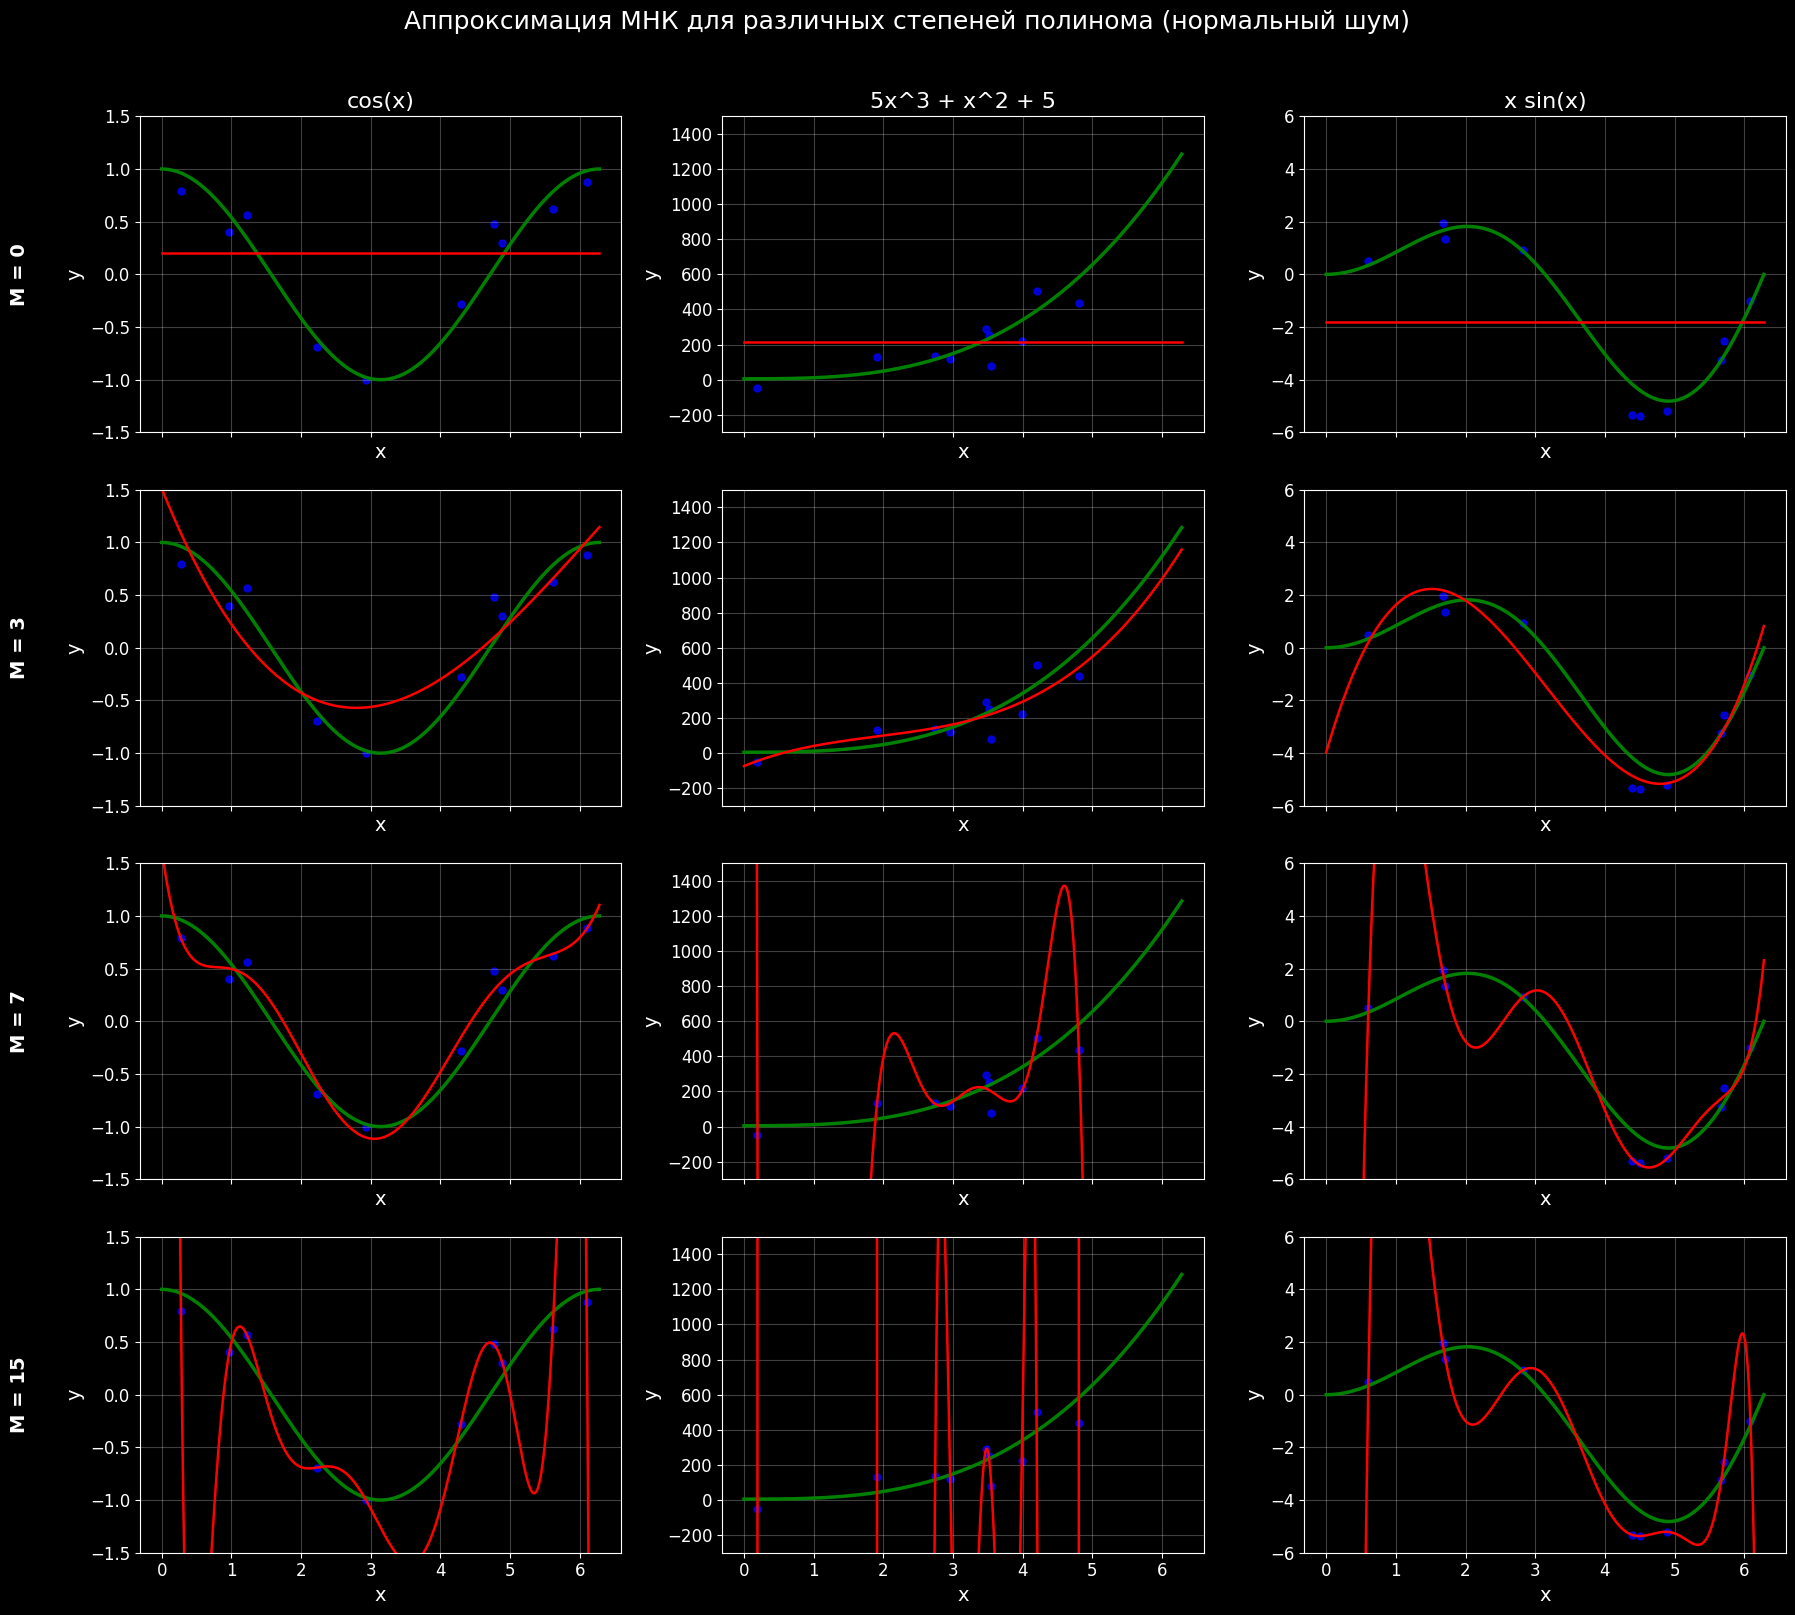

In [8]:
LIMITS = [
    (-1.5, 1.5),
    (-300, 1500),
    (-6, 6)
]

DEGREES_TO_DRAW = [0, 3, 7, 15]

fig, axes = plt.subplots(
    len(DEGREES_TO_DRAW),
    len(functions),
    figsize=(18, 16),
    sharex=True
)

for i, degree in enumerate(DEGREES_TO_DRAW):
    for j, ((func_name, func), lim) in enumerate(zip(functions.items(), LIMITS)):
        ax = axes[i, j]

        sample = samples[(func_name, "normal")]

        # Истинная функция
        ax.plot(
            x_grid,
            func(x_grid),
            color="green",
            linewidth=2.5,
            label="Истинная функция"
        )

        # Зашумлённая выборка
        ax.scatter(
            sample["x"],
            sample["y"],
            s=25,
            alpha=0.8,
            label="Зашумлённые данные",
            color="blue"
        )

        # Аппроксимация МНК заданной степени
        coef = fit_ols(sample["x"], sample["y"], degree)

        ax.plot(
            x_grid,
            predict_ols(x_grid, coef),
            linewidth=1.8,
            label=f"МНК, M={degree}",
            color="red"
        )

        ax.set_title(func_name if i == 0 else "")
        ax.set_ylim(lim[0], lim[1])
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.grid(alpha=0.25)

        # if j == 0:
        #     ax.legend()

    # Подпись степени слева от каждой строки
    axes[i, 0].annotate(
        f"M = {degree}",
        xy=(-0.25, 0.5),
        xycoords="axes fraction",
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center"
    )

fig.suptitle(
    "Аппроксимация МНК для различных степеней полинома (нормальный шум)",
    y=1.01
)

plt.tight_layout()
plt.show()


In [9]:
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.base import clone

DEGREES_TO_REGULARIZE = [0, 3, 7, 15]

# Сетка значений коэффициента регуляризации
ALPHA_GRID = np.logspace(-5, 5, 100)

# 3-блочная кросс-валидация
CV = KFold(n_splits=3, shuffle=True, random_state=SEED)

In [10]:
def fit_regularized_model(x, y, degree, model_type):
    """
    Обучение Lasso или Ridge с подбором alpha через GridSearchCV.

    Возвращает:
        best_model — лучшая модель;
        best_alpha — оптимальный коэффициент регуляризации;
        coef — коэффициенты полинома в исходном масштабе признаков.
    """

    X = design_matrix(x, degree)

    if model_type == "lasso":
        estimator = Lasso()
    elif model_type == "ridge":
        estimator = Ridge()
    else:
        raise ValueError("model_type должен быть 'lasso' или 'ridge'")

    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import StandardScaler

    if degree == 0:
        model = Pipeline([
            ("regressor", estimator)
        ])
    else:
        preprocessor = ColumnTransformer([
            ("scale", StandardScaler(), list(range(1, degree + 1)))
        ], remainder="passthrough")

        model = Pipeline([
            ("scaler", preprocessor),
            ("regressor", estimator)
        ])

    search = GridSearchCV(
        estimator=model,
        param_grid={"regressor__alpha": ALPHA_GRID},
        scoring="neg_mean_squared_error",
        cv=CV,
        n_jobs=-1
    )

    search.fit(X, y)

    best_model = search.best_estimator_
    best_alpha = search.best_params_["regressor__alpha"]
    cv_mse = -search.best_score_

    # Получаем коэффициенты в исходном масштабе z^0, z^1, ..., z^M.
    regressor = best_model.named_steps["regressor"]

    if degree == 0:
        coef = np.array([regressor.coef_[0] if np.ndim(regressor.coef_) else regressor.coef_])
    else:
        scaler = best_model.named_steps["scaler"].named_transformers_["scale"]

        coef = np.zeros(degree + 1)

        # Коэффициенты после стандартизации признаков
        coef[0] = regressor.coef_[-1] - np.sum(
            regressor.coef_[:-1] * scaler.mean_ / scaler.scale_
        )

        coef[1:] = regressor.coef_[:-1] / scaler.scale_

    return best_model, best_alpha, coef, cv_mse

In [11]:
lasso_results = []
ridge_results = []

lasso_models = {}
ridge_models = {}

for func_name, func in functions.items():

    # Только нормальный шум
    sample = samples[(func_name, "normal")]

    x_train = sample["x"]
    y_train = sample["y"]

    for degree in DEGREES_TO_REGULARIZE:
        lasso_model, lasso_alpha, lasso_coef, lasso_cv_mse = fit_regularized_model(
            x_train, y_train, degree, "lasso"
        )

        X_train = design_matrix(x_train, degree)
        X_grid = design_matrix(x_grid, degree)

        lasso_train_pred = lasso_model.predict(X_train)
        lasso_grid_pred = X_grid @ lasso_coef

        lasso_results.append({
            "M": degree,
            "func": func_name,
            "train_mse": mse(y_train, lasso_train_pred),
            "grid_mse": mse(func(x_grid), lasso_grid_pred),
            "alpha": lasso_alpha,
            "coef": lasso_coef.copy(),
            "cv_mse": lasso_cv_mse,
        })
        lasso_models[(func_name, degree)] = {
            "model": lasso_model,
            "alpha": lasso_alpha,
            "coef": lasso_coef,
            "grid_pred": lasso_grid_pred,
        }

        ridge_model, ridge_alpha, ridge_coef, ridge_cv_mse = fit_regularized_model(
            x_train, y_train, degree, "ridge"
        )
        ridge_train_pred = ridge_model.predict(X_train)
        ridge_grid_pred = X_grid @ ridge_coef

        ridge_results.append({
            "M": degree,
            "func": func_name,
            "train_mse": mse(y_train, ridge_train_pred),
            "grid_mse": mse(func(x_grid), ridge_grid_pred),
            "alpha": ridge_alpha,
            "coef": ridge_coef.copy(),
            "cv_mse": ridge_cv_mse,
        })

        ridge_models[(func_name, degree)] = {
            "model": ridge_model,
            "alpha": ridge_alpha,
            "coef": ridge_coef,
            "grid_pred": ridge_grid_pred
        }

lasso_table = pd.DataFrame(lasso_results).drop(columns=["coef", "cv_mse"])
ridge_table = pd.DataFrame(ridge_results).drop(columns=["coef", "cv_mse"])

print()
print("LASSO")
display(lasso_table.round(5))

print("RIDGE")
display(ridge_table.round(5))

/home/llirik42/PycharmProjects/Polynomial-Regression/.venv/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.616e-03, tolerance: 2.949e-04
  model = cd_fast.enet_coordinate_descent(
/home/llirik42/PycharmProjects/Polynomial-Regression/.venv/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.736e-02, tolerance: 2.850e-04
  model = cd_fast.enet_coordinate_descent(
/home/llirik42/PycharmProjects/Polynomial-Regression/.venv/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to inc


LASSO


,M,func,train_mse,grid_mse,alpha
0,0,cos(x),0.37218,0.50050,0.00001
1,3,cos(x),0.09774,0.09057,0.06893
2,7,cos(x),0.10055,0.09771,0.08697
3,15,cos(x),0.10055,0.09771,0.08697
4,0,5x^3 + x^2 + 5,25089.84621,240222.53848,0.00001
5,3,5x^3 + x^2 + 5,14049.67845,193095.91769,73.90722
6,7,5x^3 + x^2 + 5,14049.67845,193095.91769,73.90722
7,15,5x^3 + x^2 + 5,14049.67845,193095.91769,73.90722
8,0,x sin(x),7.66967,6.32341,0.00001
9,3,x sin(x),0.43279,2.36200,0.06893


RIDGE


,M,func,train_mse,grid_mse,alpha
0,0,cos(x),0.37218,0.50050,0.00001
1,3,cos(x),0.09418,0.09617,1.78865
2,7,cos(x),0.11648,0.12397,3.59381
3,15,cos(x),0.08978,0.09439,2.25702
4,0,5x^3 + x^2 + 5,25089.84621,240222.53848,0.00001
5,3,5x^3 + x^2 + 5,7814.19615,109781.91465,1.78865
6,7,5x^3 + x^2 + 5,20796.53589,228926.70848,187.38174
7,15,5x^3 + x^2 + 5,24967.70831,240009.68935,19630.40650
8,0,x sin(x),7.66967,6.32341,0.00001
9,3,x sin(x),0.48284,2.38121,0.17475


In [12]:
print("LASSO")

for func_name in functions:
    print(f"\nФункция: {func_name}")

    for degree in DEGREES_TO_REGULARIZE:
        info = lasso_models[(func_name, degree)]
        print(f"M={degree}, coef={np.round(info['coef'], 6).tolist()}")


print("\n" + "=" * 70)
print("RIDGE")

for func_name in functions:
    print(f"\nФункция: {func_name}")

    for degree in DEGREES_TO_REGULARIZE:
        info = ridge_models[(func_name, degree)]
        print(f"M={degree}, coef={np.round(info['coef'], 6).tolist()}")

LASSO

Функция: cos(x)
M=0, coef=[0.0]
M=3, coef=[-0.635752, 0.0, 1.594386, 0.0]
M=7, coef=[-0.610778, 0.0, 1.531754, 0.0, 0.0, 0.0, -0.0, -0.0]
M=15, coef=[-0.610778, 0.0, 1.531754, 0.0, 0.0, 0.0, -0.0, -0.0, -0.0, -0.0, -0.0, -0.0, -0.0, -0.0, -0.0, -0.0]

Функция: 5x^3 + x^2 + 5
M=0, coef=[0.0]
M=3, coef=[0.311185, 137.989676, -0.0, 0.0]
M=7, coef=[0.311185, 137.989676, -0.0, 0.0, -0.0, 0.0, -0.0, 0.0]
M=15, coef=[0.311185, 137.989676, -0.0, 0.0, -0.0, 0.0, -0.0, 0.0, -0.0, 0.0, -0.0, 0.0, -0.0, 0.0, -0.0, 0.0]

Функция: x sin(x)
M=0, coef=[0.0]
M=3, coef=[0.34722, -9.235302, 0.033753, 10.72707]
M=7, coef=[0.337774, -8.204504, -0.0, 4.500352, 0.0, 6.499235, 0.0, 0.0]
M=15, coef=[0.317732, -8.983326, -0.0, 7.752712, 0.118758, 3.596908, 0.0, 0.0, 0.0, 0.0, -0.0, -0.0, -0.0, -0.0, -0.0, -0.0]

RIDGE

Функция: cos(x)
M=0, coef=[0.0]
M=3, coef=[-0.625143, 0.131758, 1.560201, -0.142946]
M=7, coef=[-0.532455, 0.093636, 1.105506, -0.036178, 0.359074, -0.050027, 0.015771, -0.044306]
M=15, co

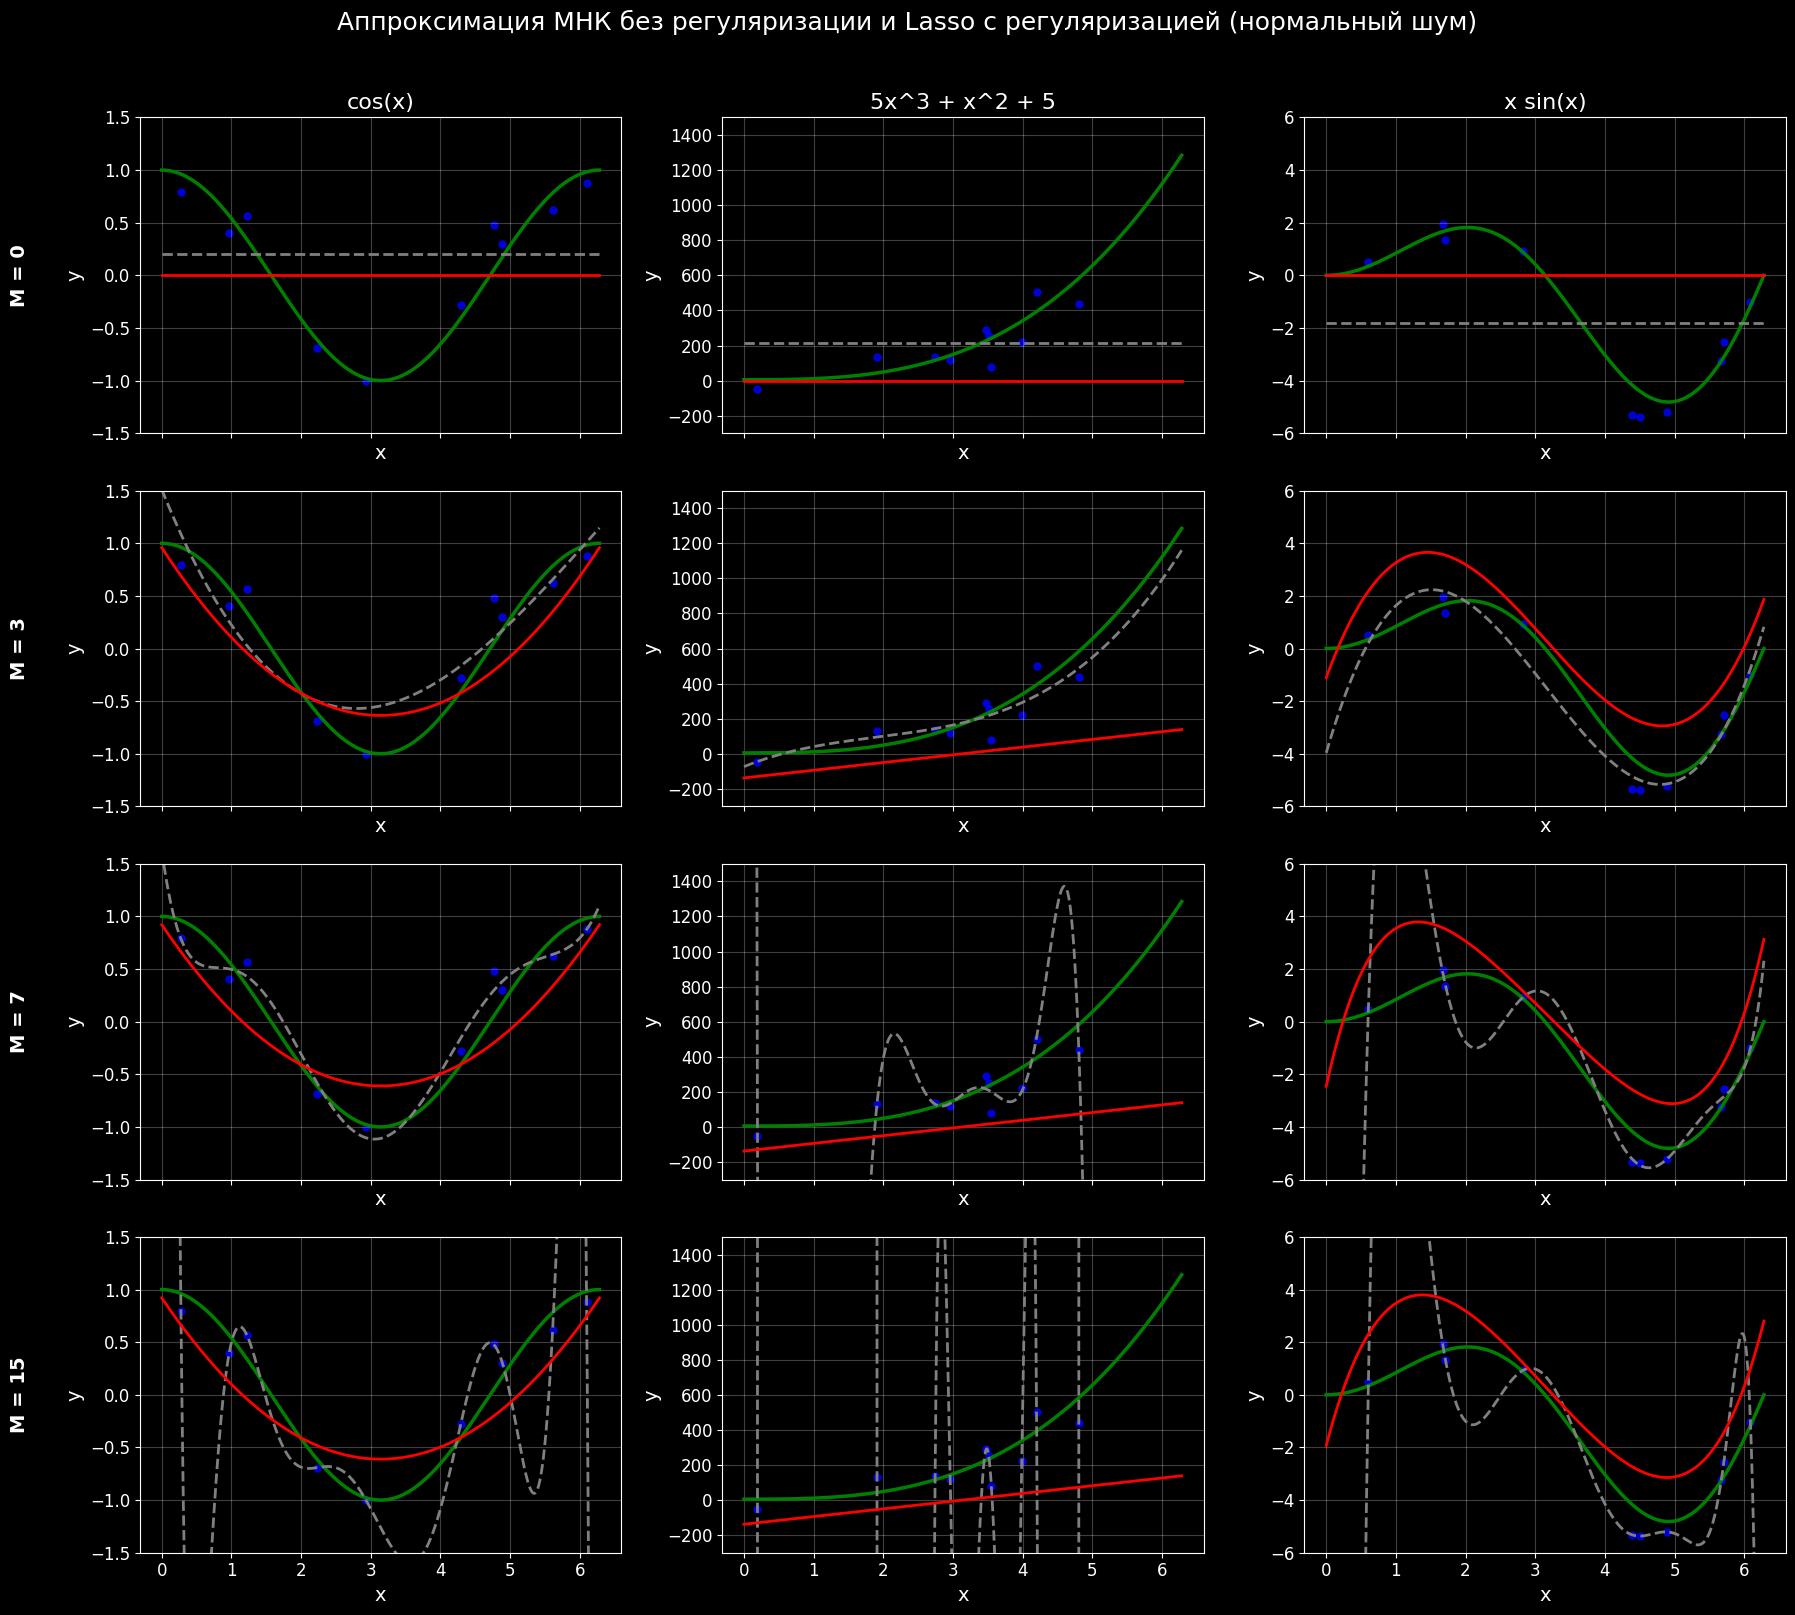

In [13]:
LIMITS = [
    (-1.5, 1.5),
    (-300, 1500),
    (-6, 6)
]

fig, axes = plt.subplots(
    len(DEGREES_TO_REGULARIZE),
    len(functions),
    figsize=(18, 16),
    sharex=True
)

for i, degree in enumerate(DEGREES_TO_REGULARIZE):

    for j, ((func_name, func), lim) in enumerate(zip(functions.items(), LIMITS)):

        ax = axes[i, j]
        sample = samples[(func_name, "normal")]

        # Истинная функция
        ax.plot(
            x_grid,
            func(x_grid),
            color="green",
            linewidth=2.5,
            label="Истинная функция"
        )

        # Обучающая выборка
        ax.scatter(
            sample["x"],
            sample["y"],
            s=25,
            alpha=0.8,
            color="blue",
            label="Выборка"
        )

        # МНК без регуляризации
        ols_coef = fit_ols(
            sample["x"],
            sample["y"],
            degree
        )

        ax.plot(
            x_grid,
            predict_ols(x_grid, ols_coef),
            color="grey",
            linewidth=2,
            label="МНК (без регуляризации)",
            linestyle="--",
        )

        # Lasso с регуляризацией
        lasso_info = lasso_models[(func_name, degree)]

        ax.plot(
            x_grid,
            lasso_info["grid_pred"],
            color="red",
            linewidth=2,
            label=f"Lasso (с регуляризацией), α={lasso_info['alpha']:.2g}"
        )

        ax.set_title(func_name if i == 0 else "")
        ax.set_ylim(lim)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        #ax.legend()

    axes[i, 0].annotate(
        f"M = {degree}",
        xy=(-0.25, 0.5),
        xycoords="axes fraction",
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center"
    )

fig.suptitle(
    "Аппроксимация МНК без регуляризации и Lasso с регуляризацией (нормальный шум)",
    y=1.01
)

plt.tight_layout()
plt.show()

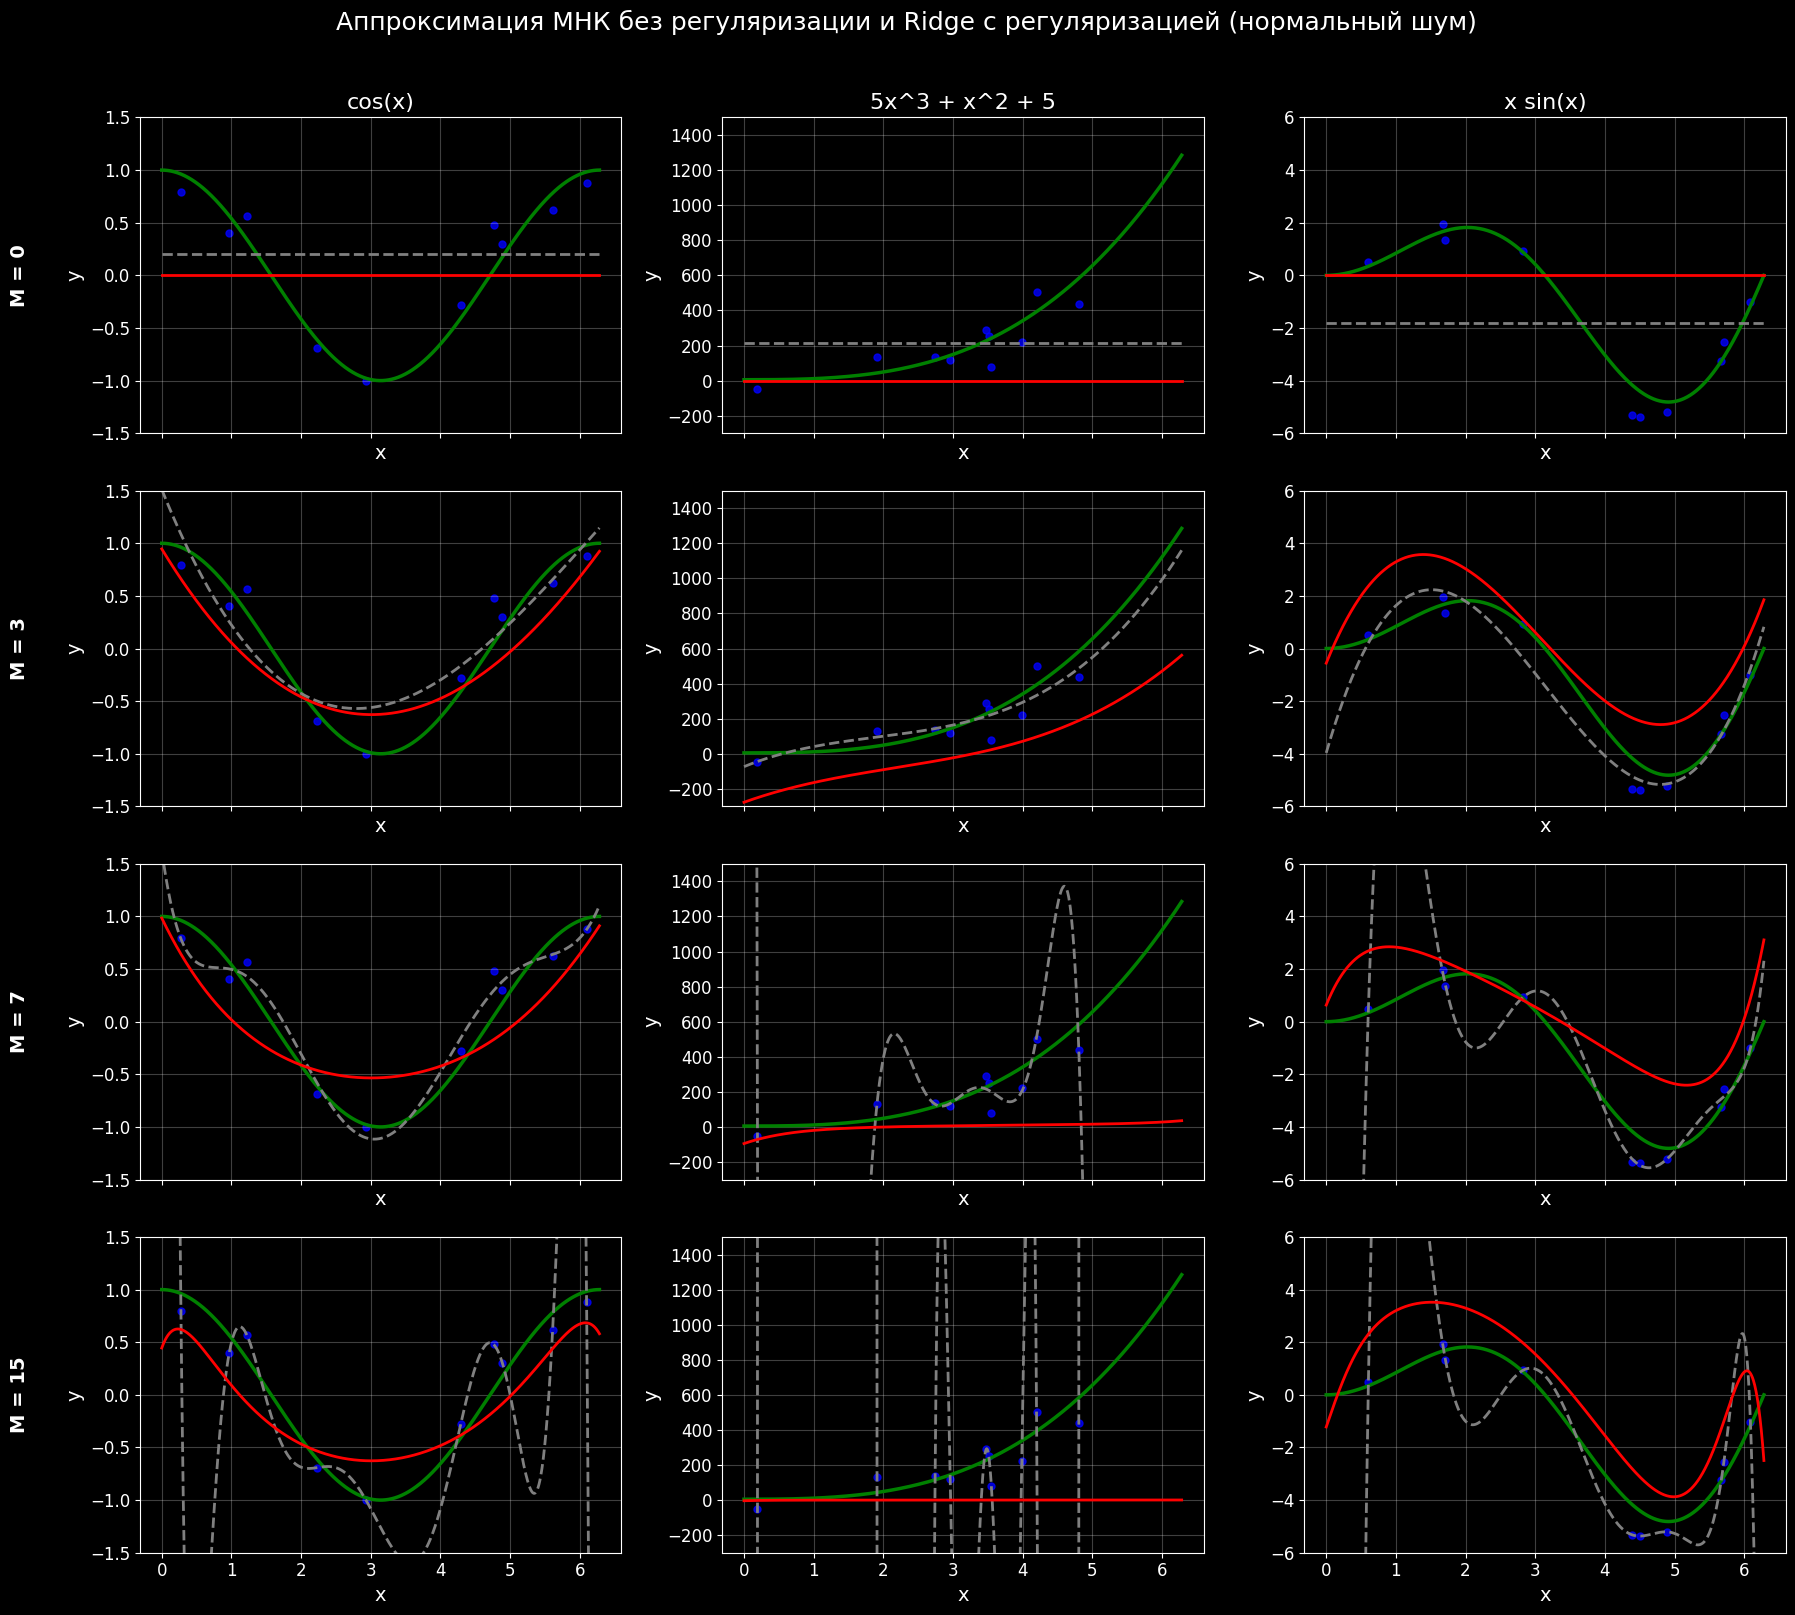

In [14]:
fig, axes = plt.subplots(
    len(DEGREES_TO_REGULARIZE),
    len(functions),
    figsize=(18, 16),
    sharex=True
)

for i, degree in enumerate(DEGREES_TO_REGULARIZE):

    for j, ((func_name, func), lim) in enumerate(zip(functions.items(), LIMITS)):

        ax = axes[i, j]
        sample = samples[(func_name, "normal")]

        # Истинная функция
        ax.plot(
            x_grid,
            func(x_grid),
            color="green",
            linewidth=2.5,
            label="Истинная функция"
        )

        # Обучающая выборка
        ax.scatter(
            sample["x"],
            sample["y"],
            s=25,
            alpha=0.8,
            color="blue",
            label="Выборка"
        )

        # МНК без регуляризации
        ols_coef = fit_ols(
            sample["x"],
            sample["y"],
            degree
        )

        ax.plot(
            x_grid,
            predict_ols(x_grid, ols_coef),
            color="grey",
            linewidth=2,
            label="МНК (без регуляризации)",
            linestyle="--",
        )

        # Ridge с регуляризацией
        ridge_info = ridge_models[(func_name, degree)]

        ax.plot(
            x_grid,
            ridge_info["grid_pred"],
            color="red",
            linewidth=2,
            label=f"Ridge (с регуляризацией), α={ridge_info['alpha']:.2g}"
        )

        ax.set_title(func_name if i == 0 else "")
        ax.set_ylim(lim)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        #ax.legend()

    axes[i, 0].annotate(
        f"M = {degree}",
        xy=(-0.25, 0.5),
        xycoords="axes fraction",
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center"
    )

fig.suptitle(
    "Аппроксимация МНК без регуляризации и Ridge с регуляризацией (нормальный шум)",
    y=1.01
)

plt.tight_layout()
plt.show()

In [15]:
# ДАЛЕЕ ВЫБОРКА С БОЛЬШИМ ЧИСЛОМ СЭМПЛОВ И БОЛЬШИМ ШУМОМ

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

functions = {
    "cos(x)": np.cos,
    "5x^3 + x^2 + 5": lambda x: 5 * x**3 + x**2 + 5,
    "x sin(x)": lambda x: x * np.sin(x),
}

NOISE_KINDS = ("uniform", "normal")

SEED = 42

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams.update({
    "font.size": 14,          # Общий размер шрифта
    "axes.titlesize": 16,     # Заголовки графиков
    "axes.labelsize": 14,     # Подписи осей
    "xtick.labelsize": 12,    # Подписи делений X
    "ytick.labelsize": 12,    # Подписи делений Y
    "legend.fontsize": 12,    # Легенда
    "figure.titlesize": 18    # Общий заголовок рисунка
})

In [17]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

In [18]:
N_LARGE = 500
LARGE_NOISE_FRACTION = 0.5

X_MAX_VALUES = [
    2 * np.pi,
    20 * np.pi,
    200 * np.pi
]

LARGE_DEGREES = range(16)
DEGREES_TO_DRAW = [0, 3, 7, 15]

# Нормализация каждого интервала в [-1, 1]
def to_z_interval(x, x_max):
    x = np.asarray(x, dtype=float)
    return 2 * x / x_max - 1


def design_matrix_interval(x, degree, x_max):
    z = to_z_interval(x, x_max)
    return np.polynomial.polynomial.polyvander(z, degree)


def noise_sigma_interval(func, x_max):
    x_ref = np.linspace(0, x_max, 20_001)
    y_ref = func(x_ref)
    return LARGE_NOISE_FRACTION * np.ptp(y_ref)


def make_large_sample(func, n, x_max, noise_kind, rng):
    x = rng.uniform(0, x_max, size=n)

    sigma = noise_sigma_interval(func, x_max)

    if noise_kind == "uniform":
        eps = rng.uniform(
            -np.sqrt(3) * sigma,
            np.sqrt(3) * sigma,
            size=n
        )
    elif noise_kind == "normal":
        eps = rng.normal(0, sigma, size=n)
    else:
        raise ValueError("Неизвестный тип шума")

    y = func(x) + eps

    order = np.argsort(x)

    return {
        "x": x[order],
        "y": y[order],
        "sigma": sigma,
        "noise_kind": noise_kind,
        "x_max": x_max
    }


# Генерация выборок
rng_large = np.random.default_rng(SEED + 100)

large_samples = {}

for func_name, func in functions.items():
    for x_max in X_MAX_VALUES:
        for kind in NOISE_KINDS:

            large_samples[(func_name, x_max, kind)] = make_large_sample(
                func,
                N_LARGE,
                x_max,
                kind,
                rng_large
            )


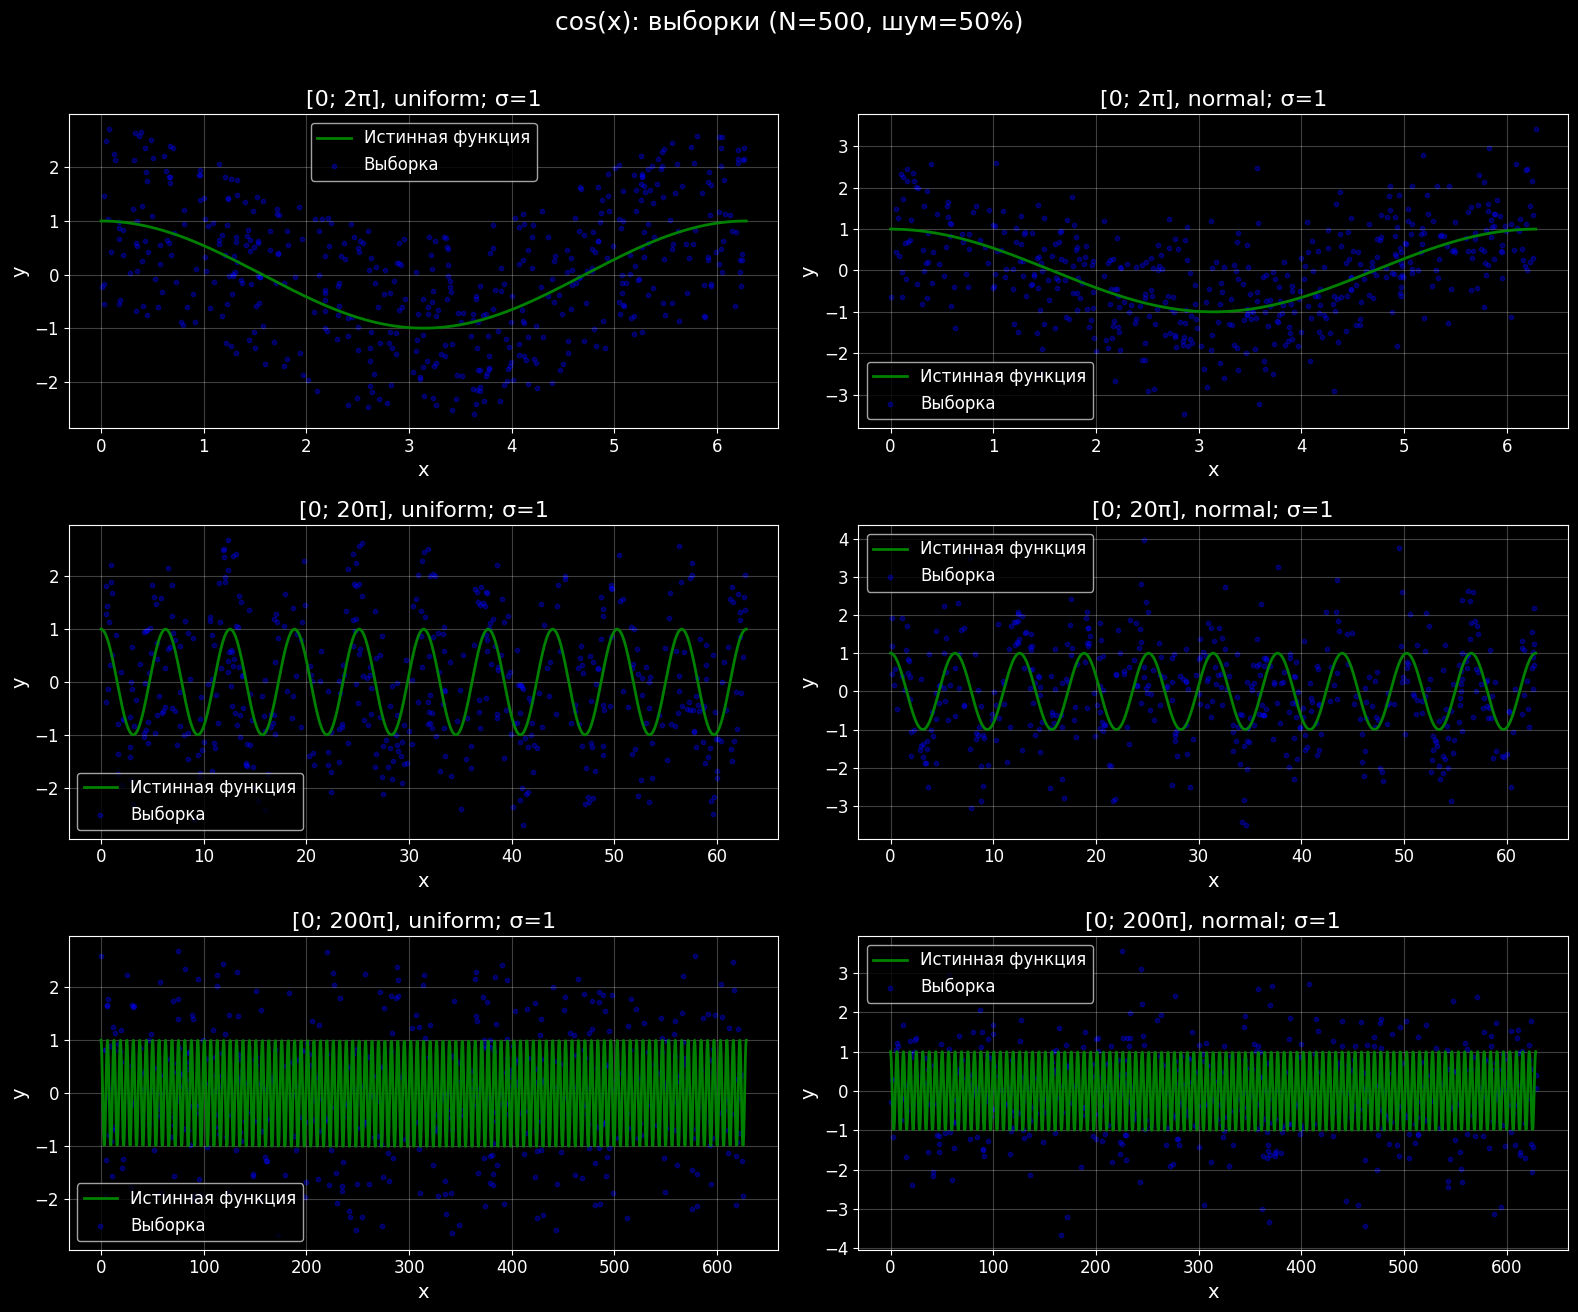

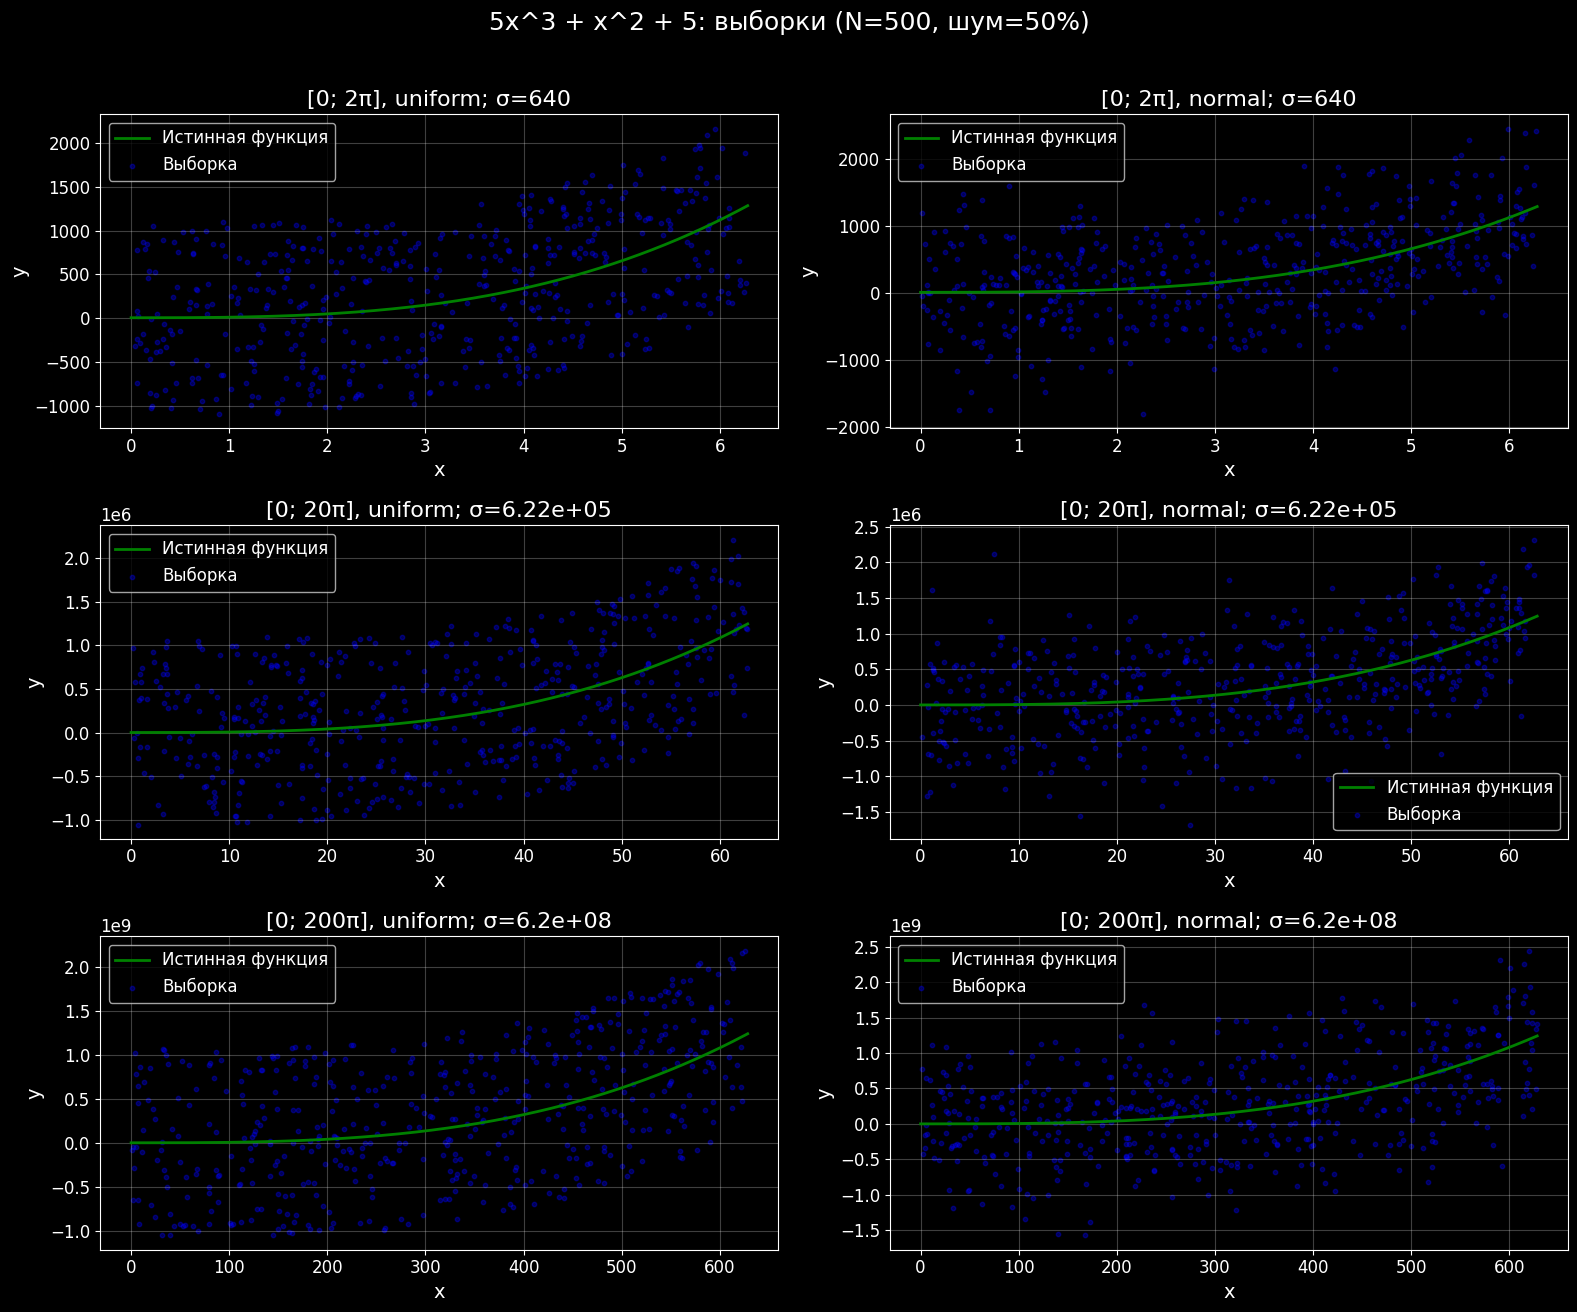

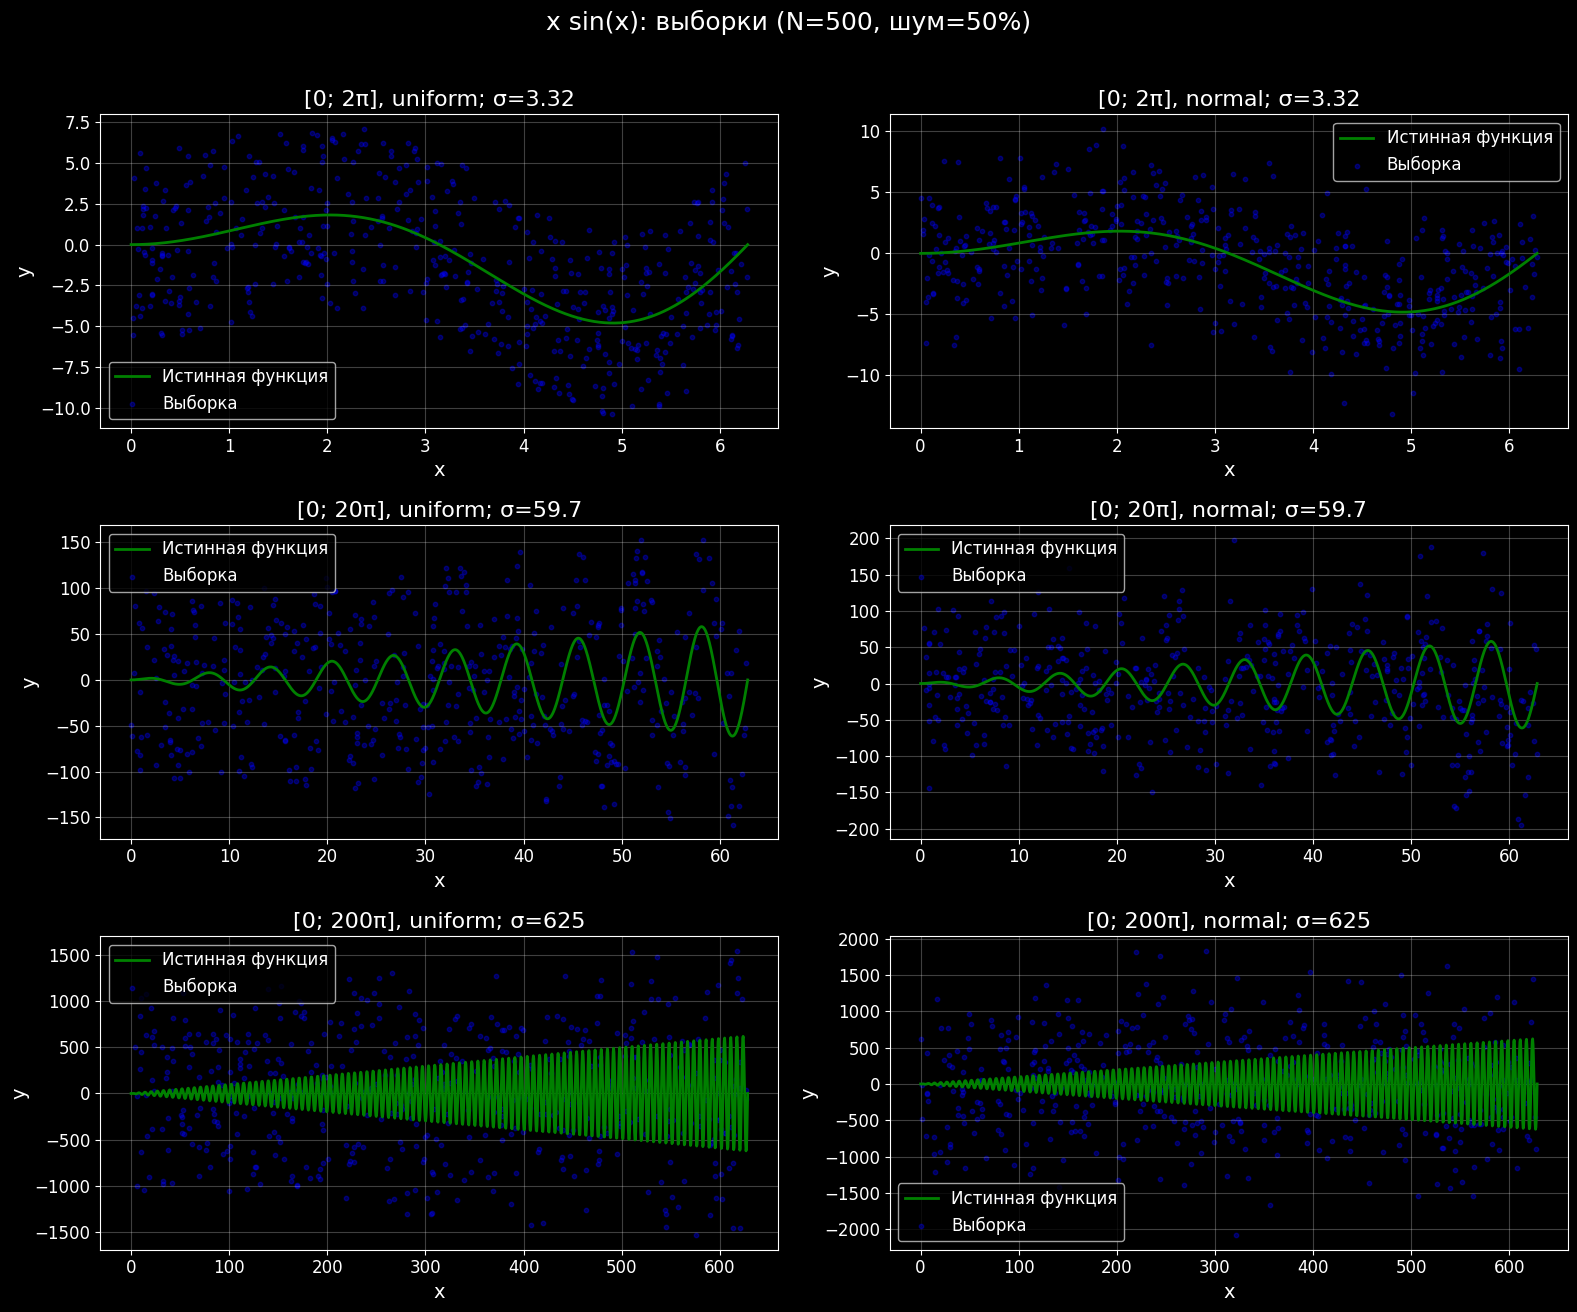

In [19]:
for func_name, func in functions.items():

    fig, axes = plt.subplots(
        3, 2,
        figsize=(16, 13)
    )

    for i, x_max in enumerate(X_MAX_VALUES):
        x_grid_large = np.linspace(0, x_max, 1500)

        for j, kind in enumerate(NOISE_KINDS):

            ax = axes[i, j]

            sample = large_samples[(func_name, x_max, kind)]

            ax.plot(
                x_grid_large,
                func(x_grid_large),
                color="green",
                linewidth=2,
                label="Истинная функция"
            )

            ax.scatter(
                sample["x"],
                sample["y"],
                s=10,
                alpha=0.35,
                color="blue",
                label="Выборка"
            )

            ax.set_title(
                f"[0; {x_max / np.pi:.0f}π], {kind}; "
                f"σ={sample['sigma']:.3g}"
            )

            ax.set_xlabel("x")
            ax.set_ylabel("y")
            ax.legend()

    fig.suptitle(
        f"{func_name}: выборки (N={N_LARGE}, "
        f"шум={int(LARGE_NOISE_FRACTION * 100)}%)",
        y=1.01
    )

    plt.tight_layout()
    plt.show()

In [20]:
def fit_ols_interval(x, y, degree, x_max):
    X = design_matrix_interval(x, degree, x_max)
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    return coef


def predict_ols_interval(x, coef, x_max):
    X = design_matrix_interval(x, len(coef) - 1, x_max)
    return X @ coef

In [21]:
large_results = {}

for func_name, func in functions.items():

    for x_max in X_MAX_VALUES:

        x_grid_large = np.linspace(0, x_max, 3000)
        y_grid_true = func(x_grid_large)

        for kind in NOISE_KINDS:

            sample = large_samples[(func_name, x_max, kind)]

            rows = []

            for degree in LARGE_DEGREES:

                coef = fit_ols_interval(
                    sample["x"],
                    sample["y"],
                    degree,
                    x_max
                )

                train_pred = predict_ols_interval(
                    sample["x"],
                    coef,
                    x_max
                )

                grid_pred = predict_ols_interval(
                    x_grid_large,
                    coef,
                    x_max
                )

                rows.append({
                    "M": degree,
                    "train_mse": mse(sample["y"], train_pred),
                    "grid_mse": mse(y_grid_true, grid_pred),
                    "coef": coef
                })

            large_results[(func_name, x_max, kind)] = pd.DataFrame(rows)

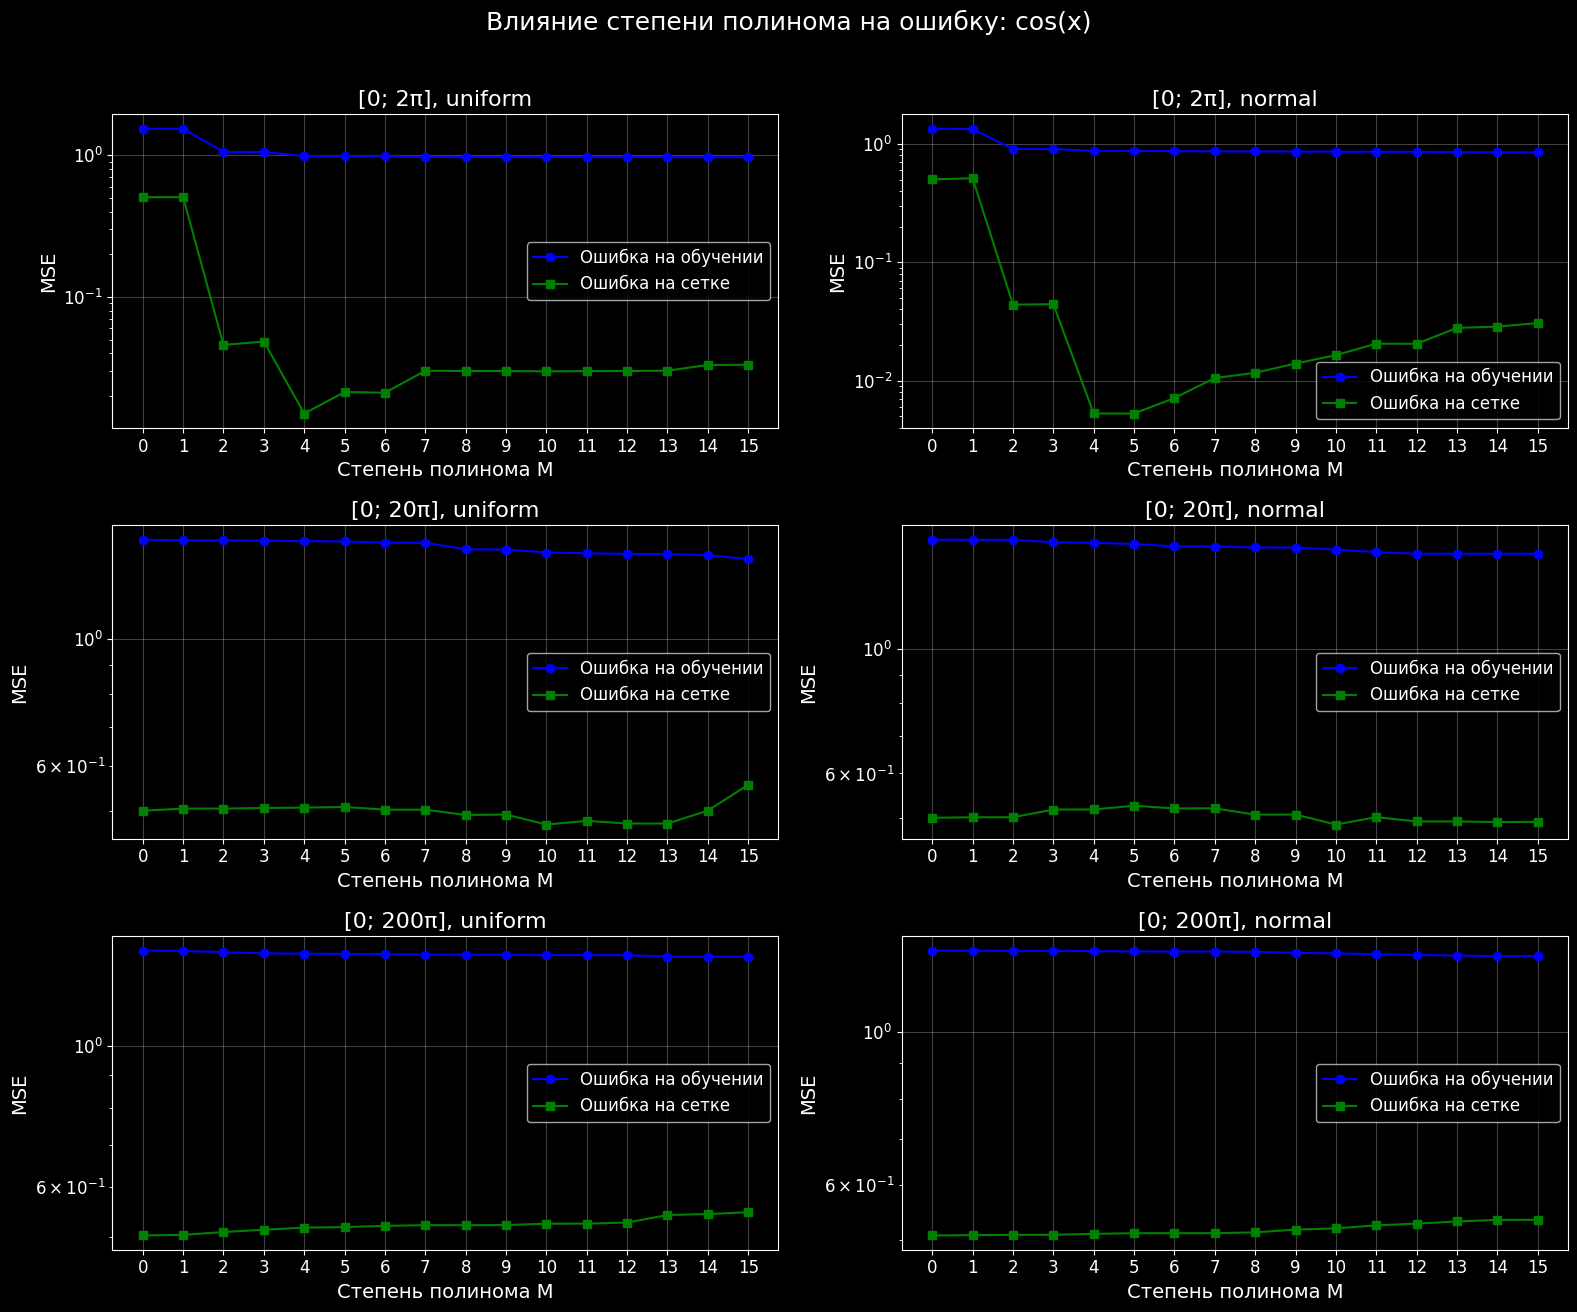

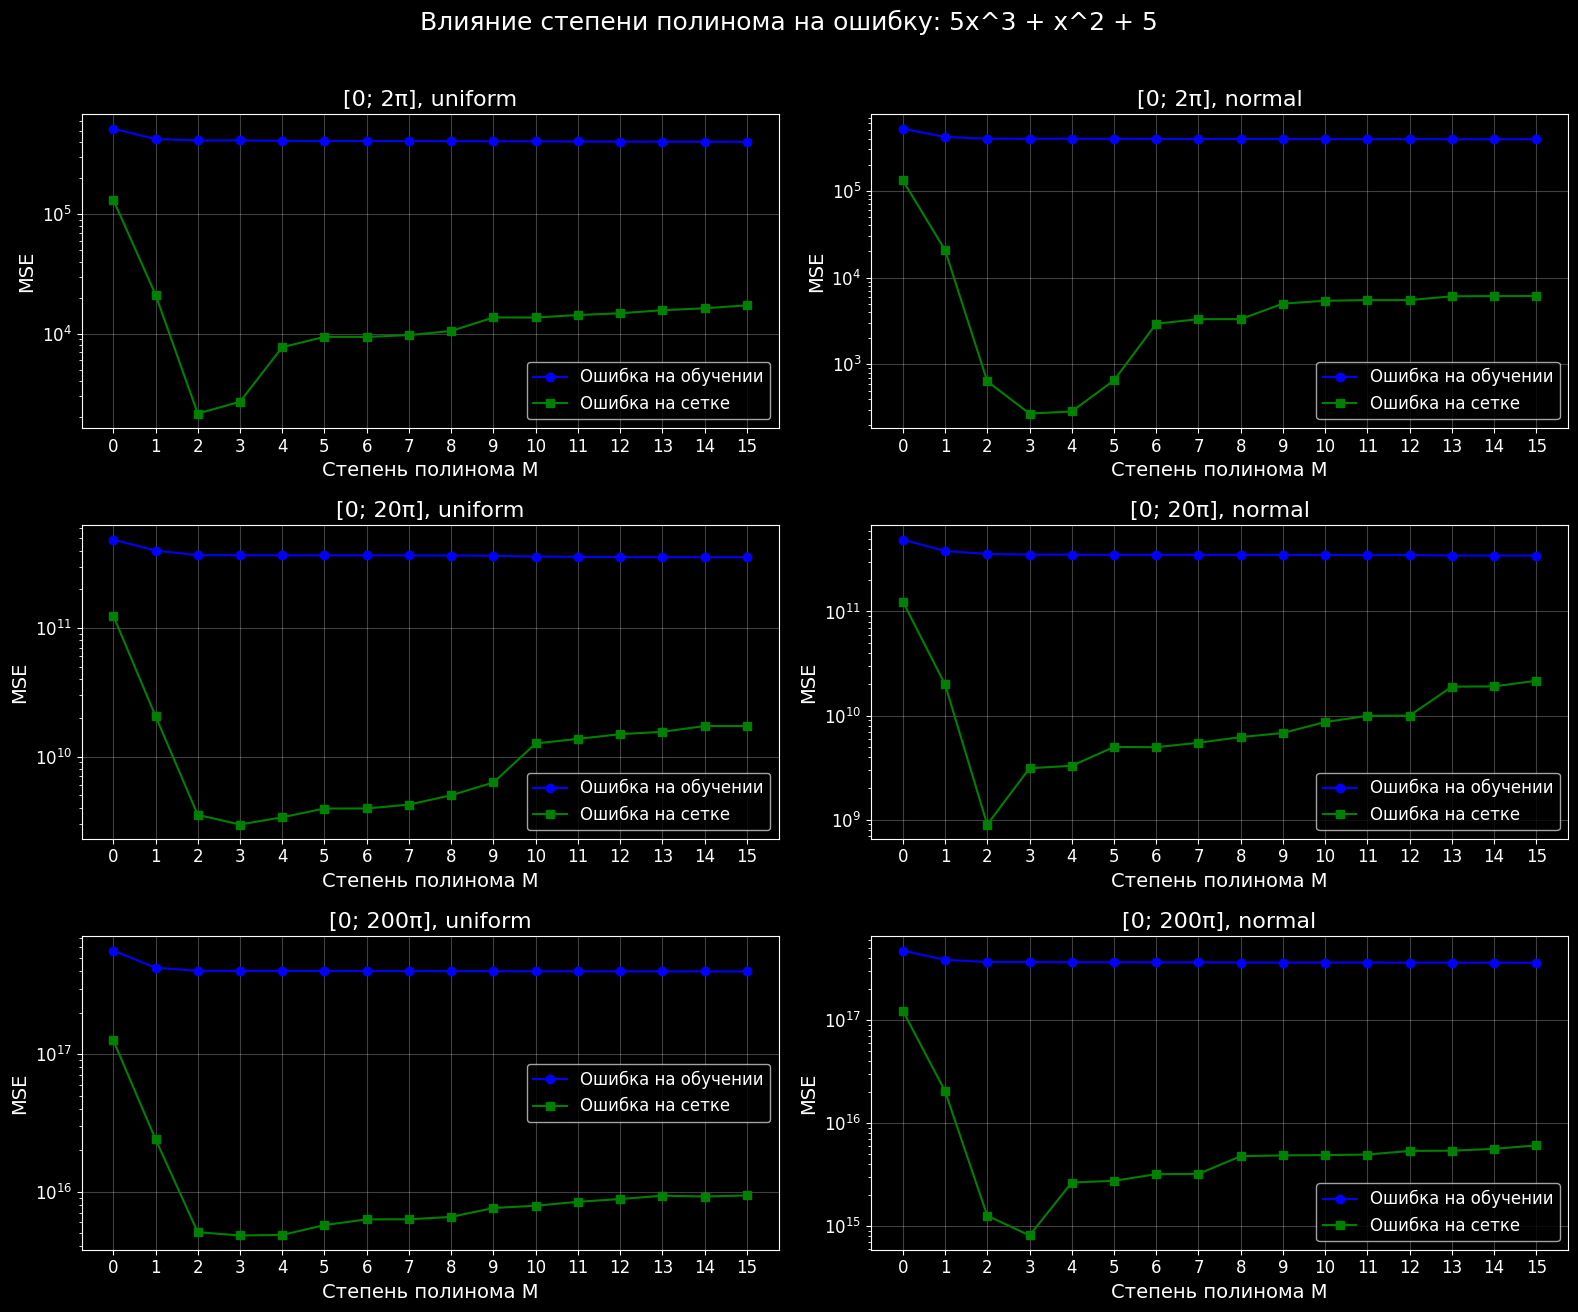

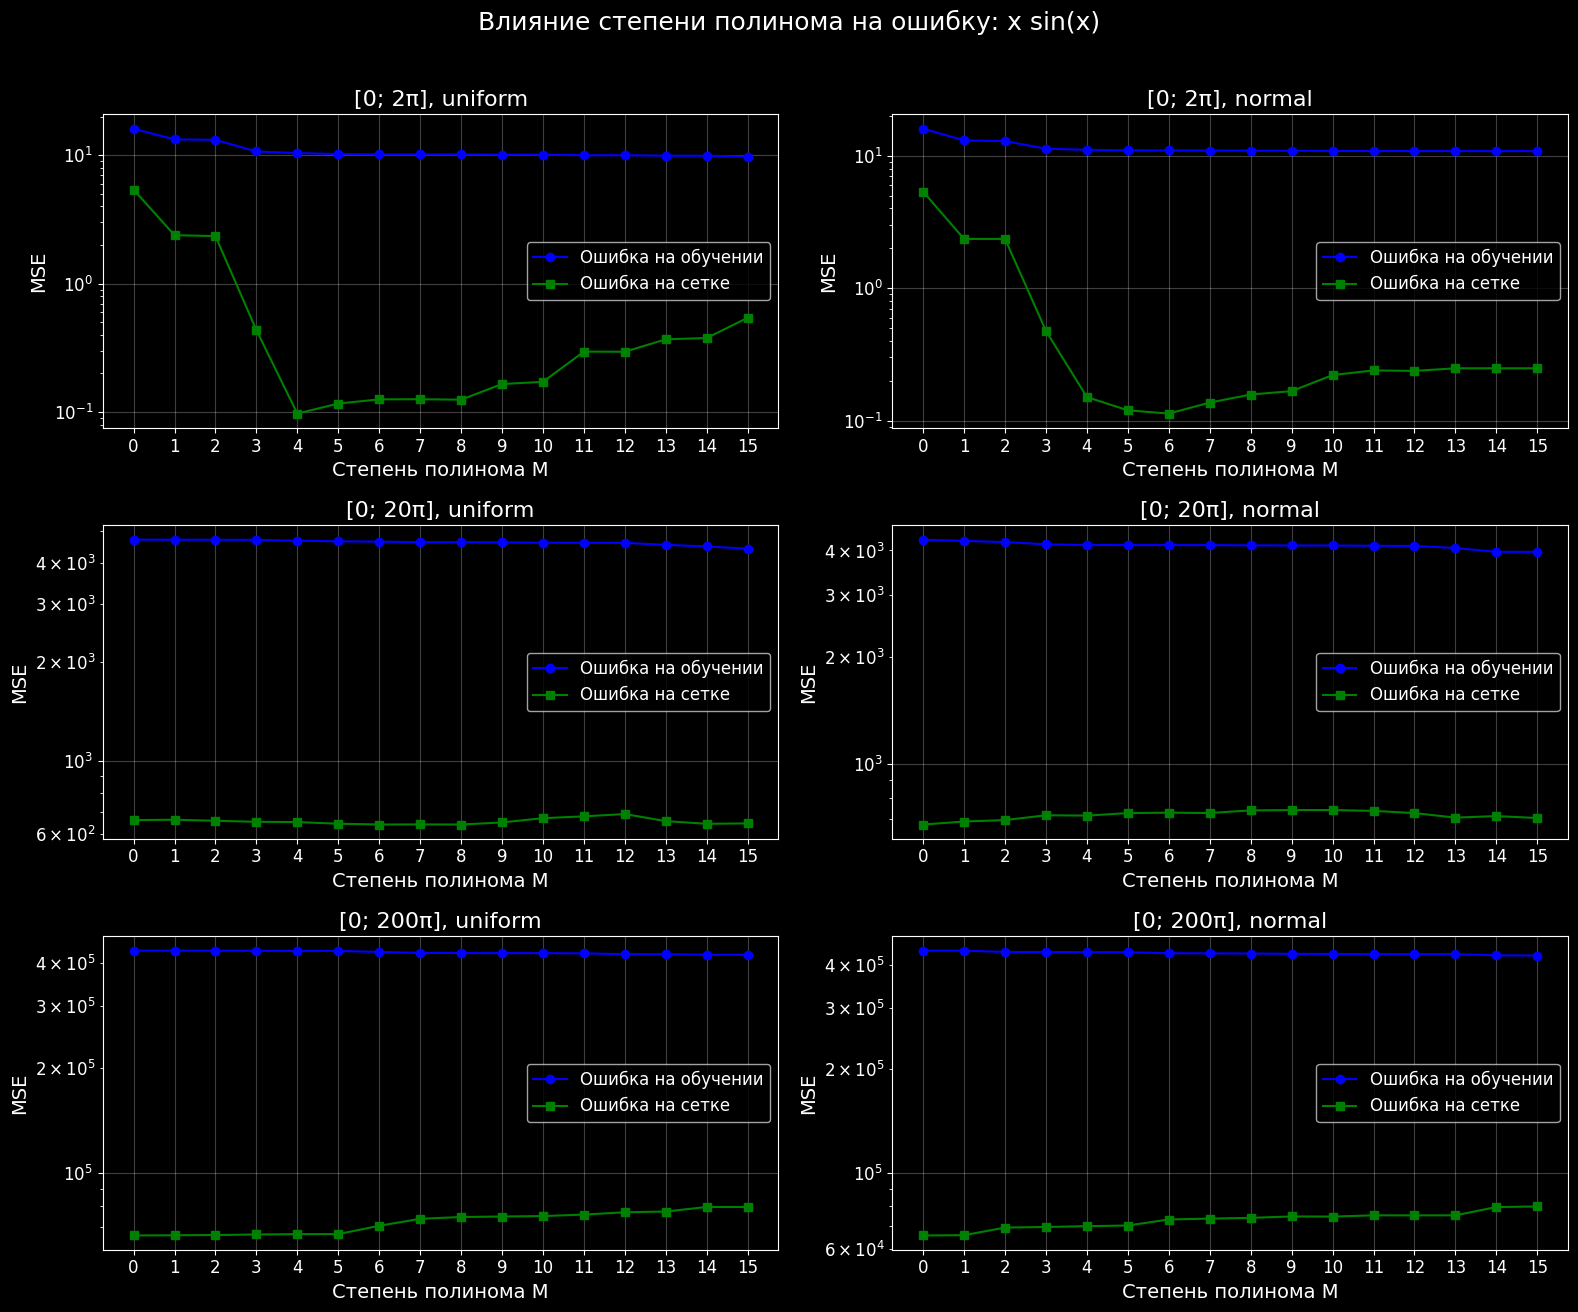

In [22]:
for func_name, func in functions.items():

    fig, axes = plt.subplots(
        3, 2,
        figsize=(16, 13)
    )

    for i, x_max in enumerate(X_MAX_VALUES):

        for j, kind in enumerate(NOISE_KINDS):

            ax = axes[i, j]

            result = large_results[(func_name, x_max, kind)]

            ax.semilogy(
                result["M"],
                result["train_mse"],
                marker="o",
                label="Ошибка на обучении",
                color="blue"
            )

            ax.semilogy(
                result["M"],
                result["grid_mse"],
                marker="s",
                label="Ошибка на сетке",
                color="green"
            )

            ax.set_title(
                f"[0; {x_max / np.pi:.0f}π], {kind}"
            )

            ax.set_xlabel("Степень полинома M")
            ax.set_ylabel("MSE")
            ax.set_xticks(list(LARGE_DEGREES))
            ax.legend()

    fig.suptitle(
        f"Влияние степени полинома на ошибку: {func_name}",
        y=1.01
    )

    plt.tight_layout()
    plt.show()

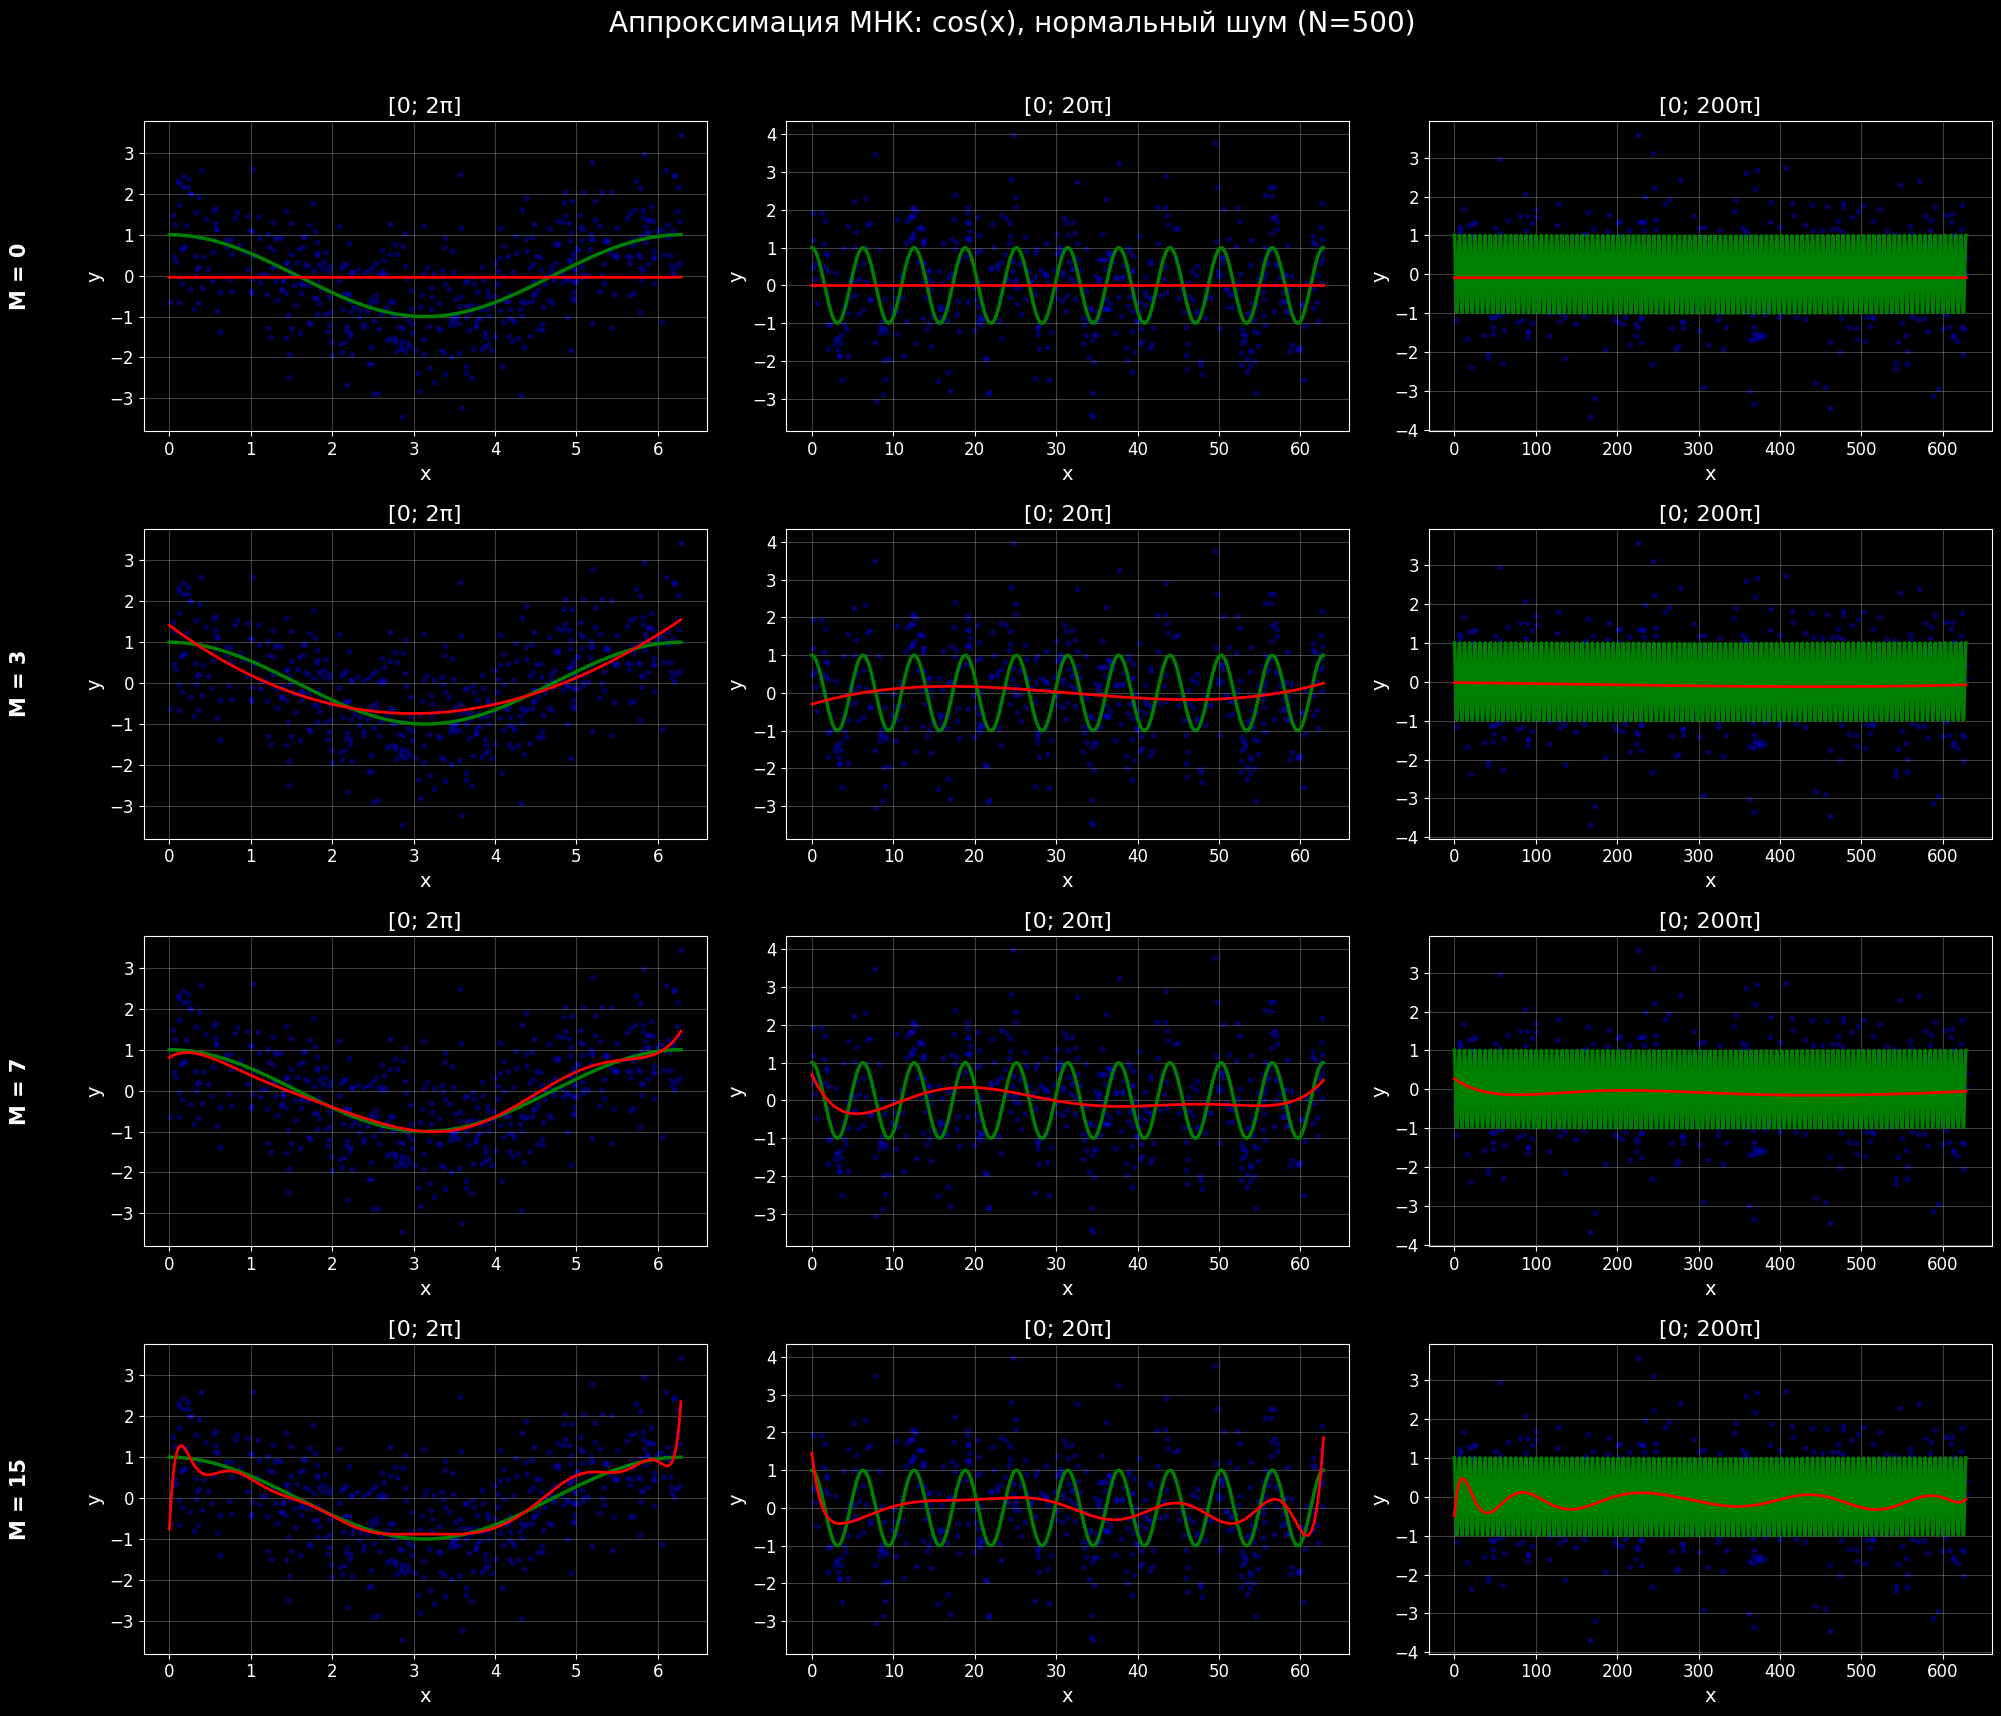

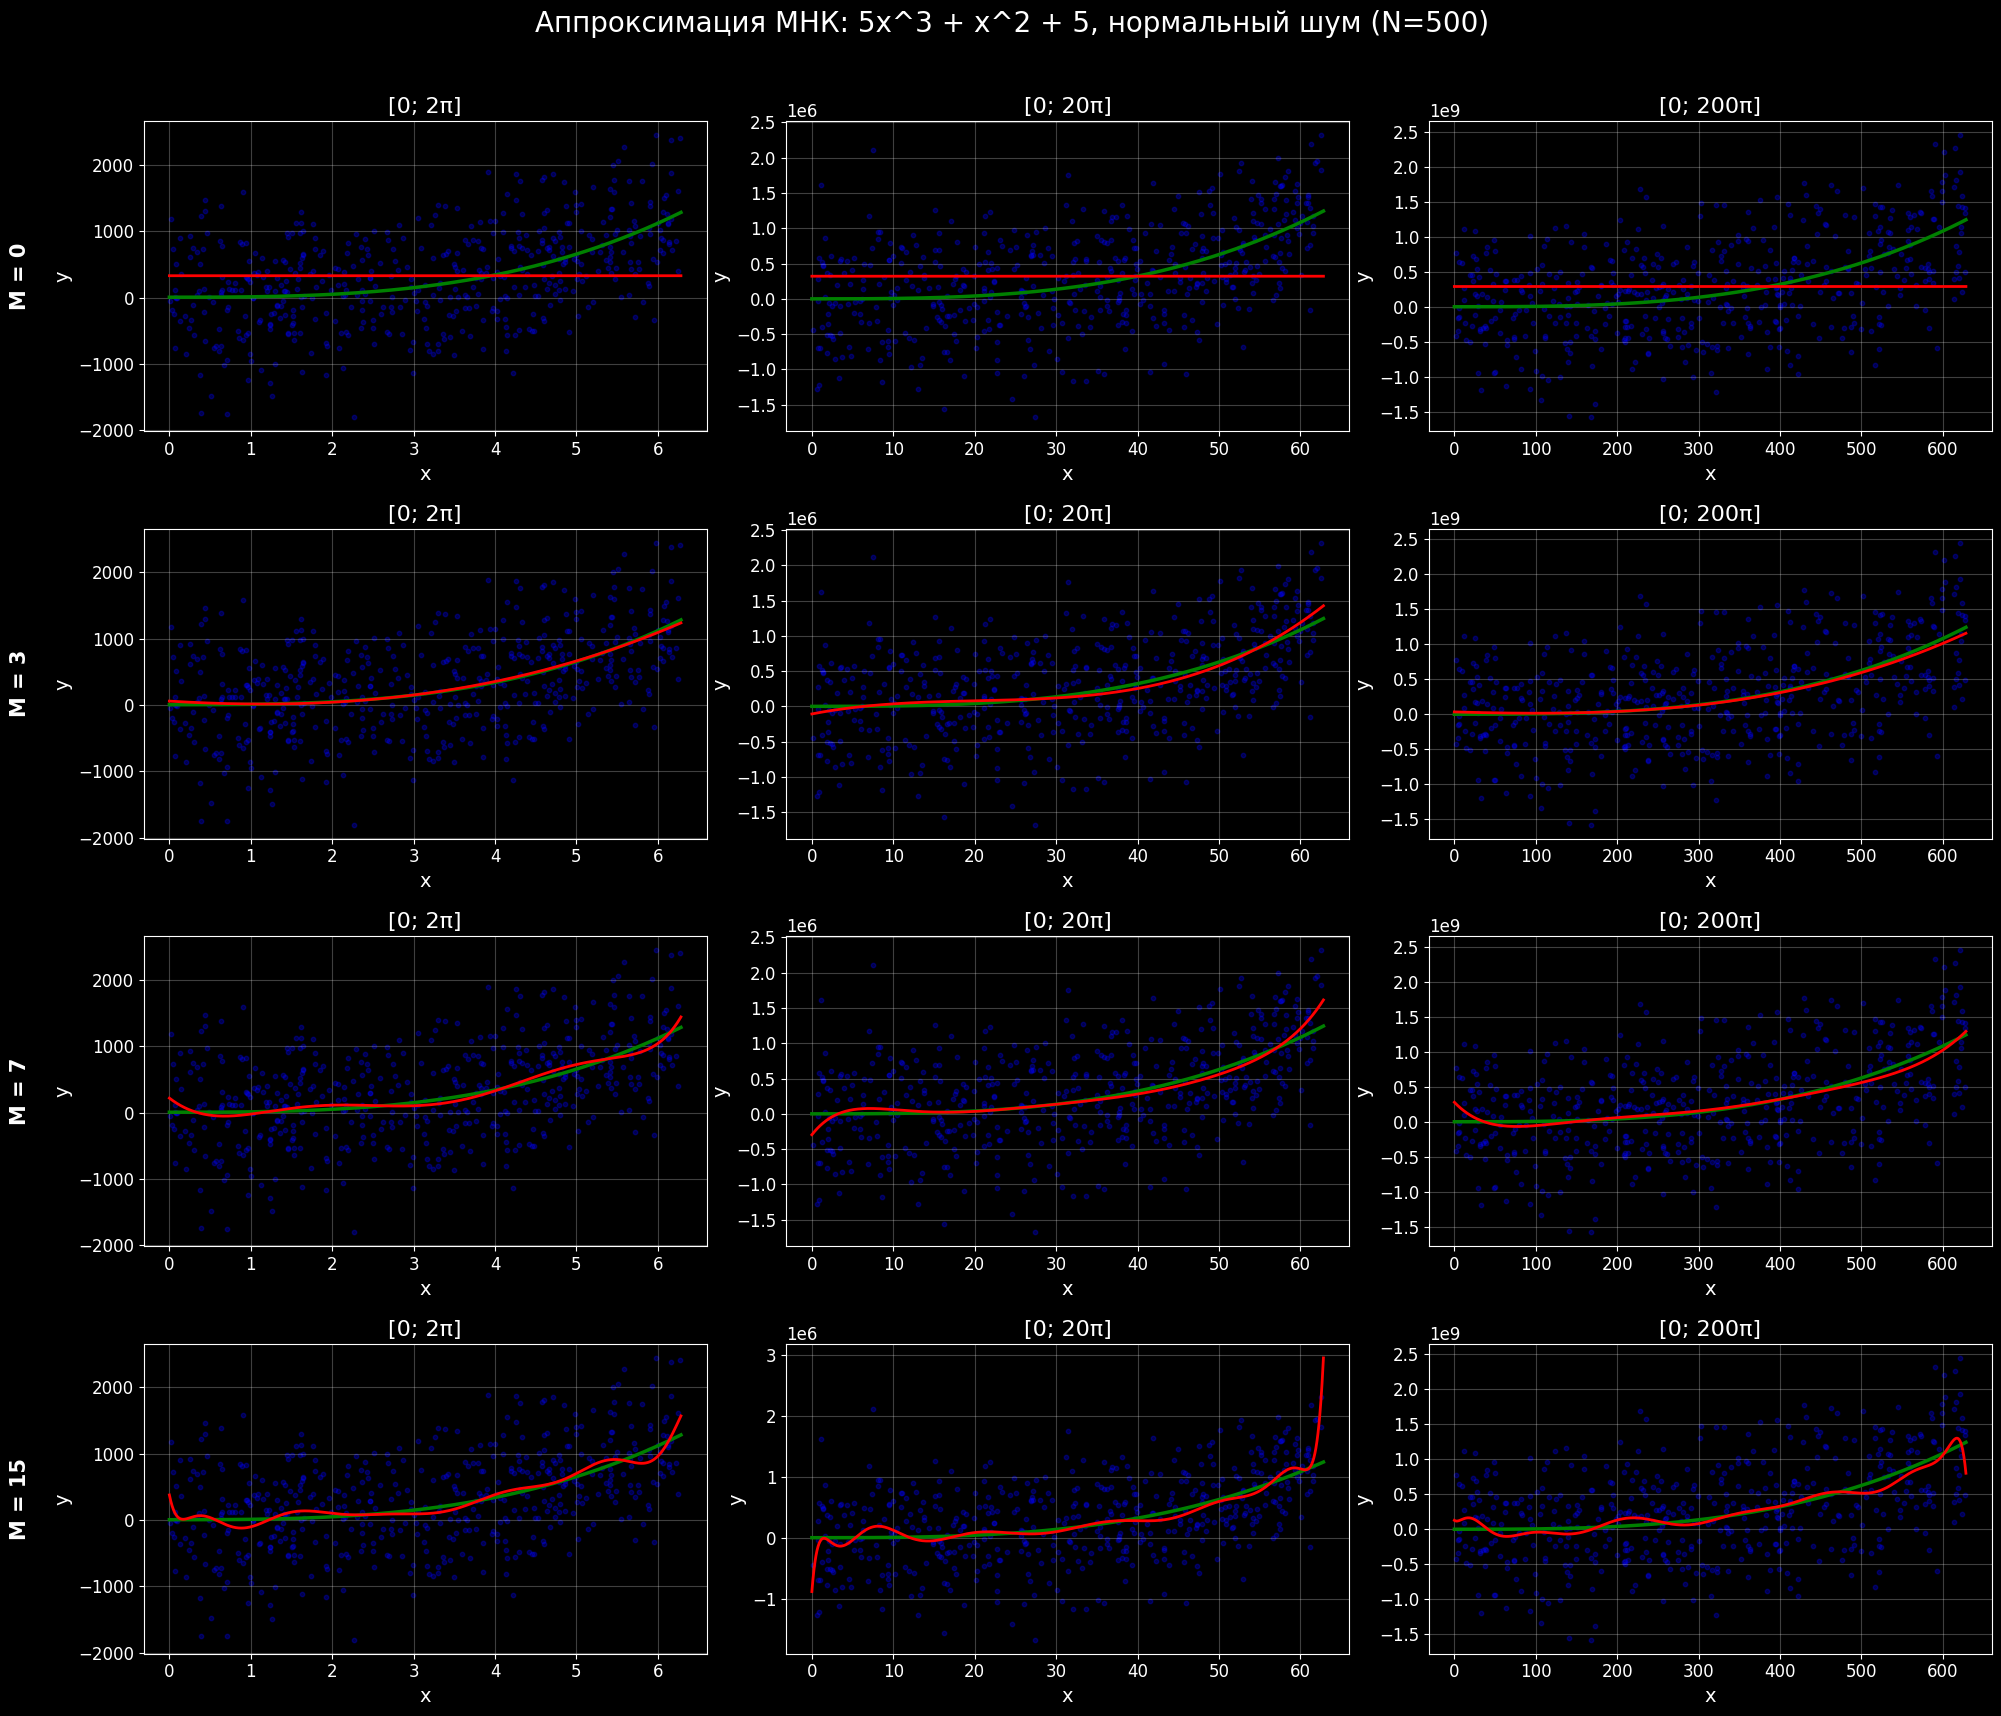

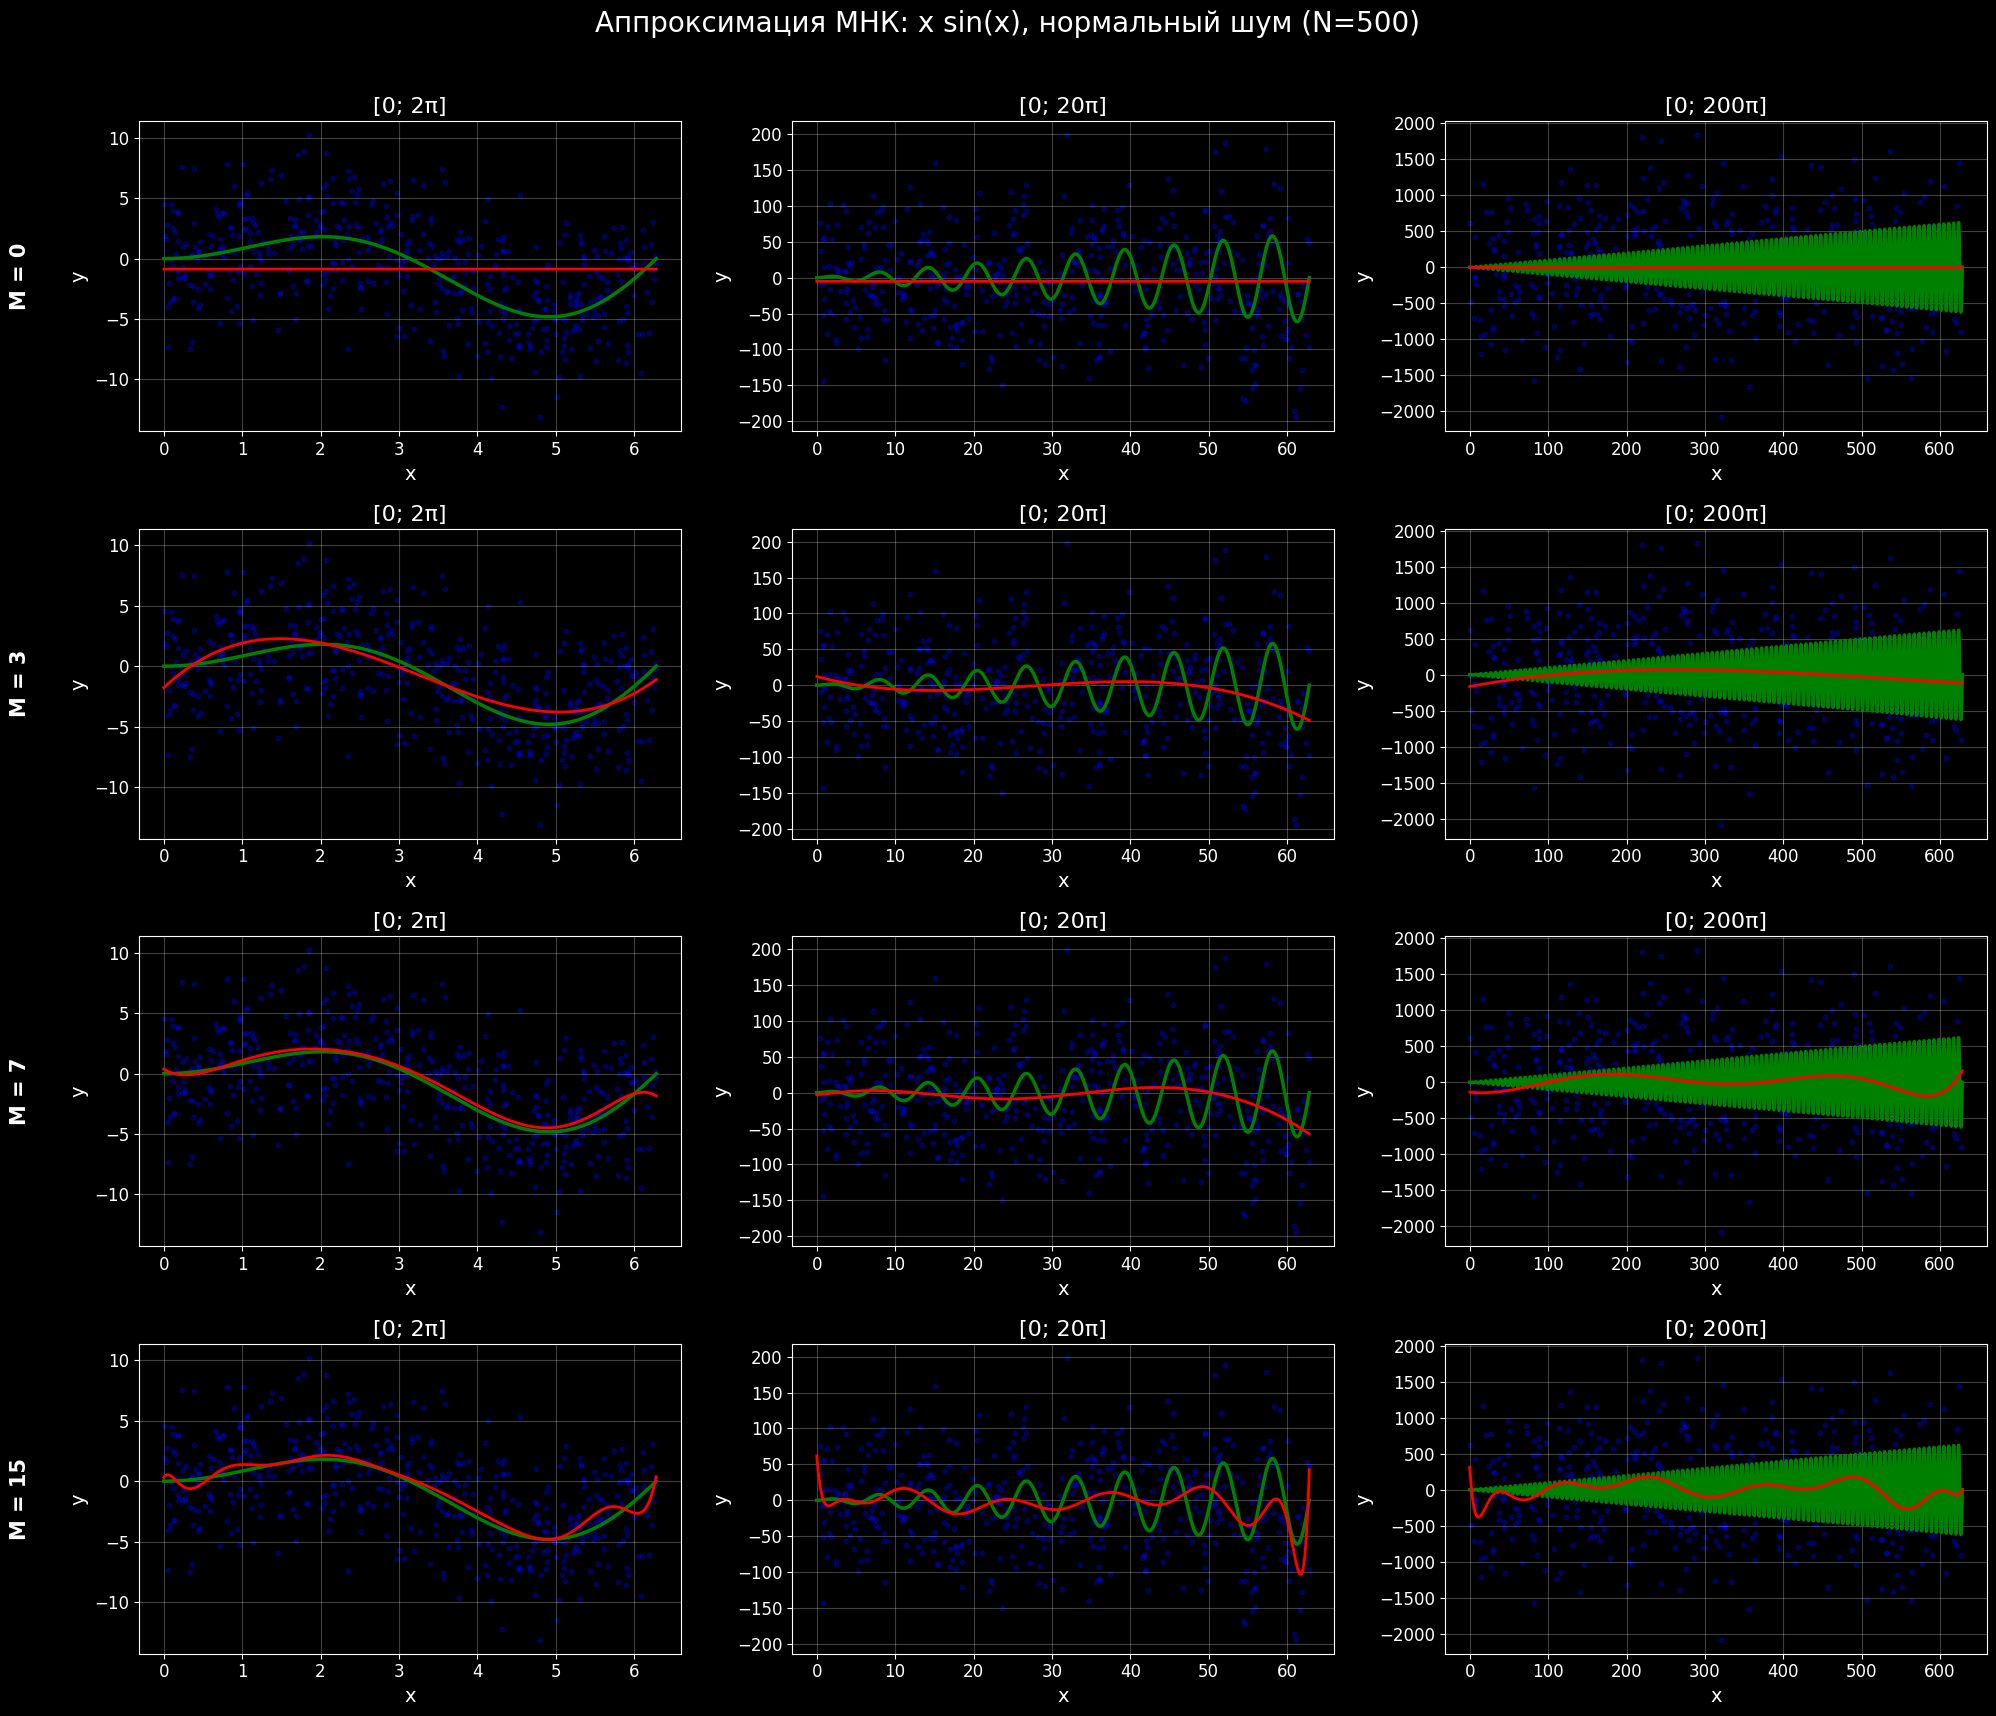

In [23]:
for func_name, func in functions.items():

    fig, axes = plt.subplots(
        len(DEGREES_TO_DRAW),
        len(X_MAX_VALUES),
        figsize=(20, 17)
    )

    for i, degree in enumerate(DEGREES_TO_DRAW):

        for j, x_max in enumerate(X_MAX_VALUES):

            ax = axes[i, j]

            sample = large_samples[(func_name, x_max, "normal")]

            x_grid_large = np.linspace(0, x_max, 1500)

            # Истинная функция
            ax.plot(
                x_grid_large,
                func(x_grid_large),
                color="green",
                linewidth=2.5,
                label="Истинная функция"
            )

            # Выборка с нормальным шумом
            ax.scatter(
                sample["x"],
                sample["y"],
                s=10,
                alpha=0.3,
                color="blue",
                label="Выборка"
            )

            # МНК
            coef = fit_ols_interval(
                sample["x"],
                sample["y"],
                degree,
                x_max
            )

            y_pred = predict_ols_interval(
                x_grid_large,
                coef,
                x_max
            )

            ax.plot(
                x_grid_large,
                y_pred,
                color="red",
                linewidth=2,
                label=f"МНК, M={degree}"
            )

            ax.set_title(
                f"[0; {x_max / np.pi:.0f}π]",
                fontsize=16
            )

            ax.set_xlabel("x", fontsize=14)
            ax.set_ylabel("y", fontsize=14)

            # Размер подписей делений осей
            ax.tick_params(
                axis="both",
                labelsize=12
            )

            ax.grid(alpha=0.25)

            # Легенда
            # if i == 0 and j == 0:
            #     ax.legend(fontsize=12)

        axes[i, 0].annotate(
            f"M = {degree}",
            xy=(-0.22, 0.5),
            xycoords="axes fraction",
            fontsize=15,
            fontweight="bold",
            rotation=90,
            ha="center",
            va="center"
        )

    fig.suptitle(
        f"Аппроксимация МНК: {func_name}, нормальный шум (N={N_LARGE})",
        fontsize=20,
        y=1.01
    )

    plt.tight_layout()
    plt.show()